# Guardian Layer (9antra) — Random Forest Reading-Trust Classifier

**TSYP14 City Brain Convergence · ML baseline notebook**

> **Read this first — data provenance.**
> When this notebook was written, the workspace contained **no `README.md` and no real sensor dataset** — only the generator script `generate_dataset.py`. This version (v0.2) uses a corrected generator, `generate_dataset_v2.py` (the original is untouched), whose labels come from **ground truth (forged vs genuine)** instead of from the evidence features. The architecture summary below therefore comes from the project brief, not from the repository README, and **every result in this notebook is computed on synthetic data produced by that generator.** Results describe how well a Random Forest recovers the *generator's* labelling rules. They are **not** evidence of real-world detection performance. The data-loading section is built so real labelled records can be dropped in later.

## 1. Project introduction

### Guardian architecture (from the project brief)
Guardian is the trust, detection and containment layer between the sensors and City Brain. It decides whether a reading can be trusted *before* City Brain drives a physical actuator.

| Layer | Purpose | Nature |
|---|---|---|
| A | Protocol validation (replay / sequence checks; signatures planned) | deterministic, **mandatory** |
| B | Physical plausibility (bounds, rate of change, z-score drift) | deterministic |
| C | Correlation with neighbouring sensors | deterministic |
| D | Command/effect validation (pending Twin data) | deterministic |
| E | Time-decayed device reputation | stateful |

Trust-score contract (existing, **not** touched by this notebook): Trusted ≥ 0.70, Degraded 0.40–0.70, Untrusted < 0.40; *Isolated* is a separate containment state. Proposed actuator minimums: R1 0.50, R2 0.70, R3 0.75 (pending confirmation).

### ML objective
Provide an **advisory anomaly-risk signal** for a single reading, learned from the same features Layers B, C and E already compute. It is *complementary*: it can flag combinations of weak signals that fixed thresholds miss, but it never replaces, overrides or relaxes a deterministic check.

### Why a Random Forest baseline
- Works well on small, tabular, mixed-type features with no scaling needed.
- Handles non-linear interactions (e.g. "out of bounds *and* uncorroborated") without hand-written rules.
- Gives out-of-the-box importances and well-behaved probabilities, and is cheap to run at the edge.
- It is a *baseline*: its job is to tell us whether learning adds anything over a trivial classifier and a shallow decision tree.

### Classification task (binary, suspicious = positive class)
| Class | Meaning (ground truth known to the generator) | Source labels |
|---|---|---|
| `0` Trusted | the reading reflects reality: normal operation, a benign change, or a **genuine incident — even if neighbours have not corroborated it yet** | `trusted` |
| `1` Suspicious | the reading was **forged**: blatant or marginal out-of-range spoof, in-range spoof, spoof with forged neighbour corroboration, slow in-range drift attack, or an **adaptive forged incident ramp with forged corroboration** | `suspect`, `compromised` |
| *excluded* | **not** used for training | `degraded`, `rejected_replay` |

**Why two labels are excluded.**
- `degraded` (natural drift, stuck sensor, dropout) is a *sensor-health* condition, not an attack. Calling it "suspicious" would teach the model that faults are malicious. It is analysed separately in Section 8. (Natural drift is simulated milder than attack drift — an assumption; real faults and slow attacks can look alike.)
- `rejected_replay` is handled by **Layer A**, which must stay deterministic. Replay rows in the generator also carry ordinary-looking numeric features (an old, plausible value), so a classifier cannot learn them honestly.

**Input features:** domain, normalised reading, short-window z-score, normalised rate of change, out-of-bounds flag, neighbour-correlation strength, whether the reading claims an incident, decayed reputation flags, deviation from a 30-tick baseline, and the length of a flat (stuck) run. Raw identifiers (`node_id`, `scenario_id`, `timestamp`, `tick`, `scenario_type`) are *not* inputs.

## 2. Environment and imports

Install (only if something is missing):
```bash
pip install pandas numpy matplotlib seaborn scikit-learn joblib pyarrow
```
`pyarrow` is only needed to read Parquet files.

In [1]:
import datetime as dt
import importlib.util
import json
import os
import shutil
import platform
import subprocess
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             classification_report, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

print("python", platform.python_version(), "| sklearn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.13.16 | sklearn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


In [2]:
# ---------------------------------------------------------------------------
# CONFIGURATION — edit this cell to point the notebook at real data.
# ---------------------------------------------------------------------------
PROJECT_DIR = Path(".").resolve()

# Set DATA_PATH to a real labelled file (.csv / .json / .jsonl / .parquet).
# Leave None to auto-discover; if nothing real is found, a SYNTHETIC demo set is generated.
DATA_PATH = None
DATA_SEARCH_DIRS = [PROJECT_DIR, PROJECT_DIR / "data"]

# Target configuration. The target column is never guessed.
TARGET_COL = "label"
TRUSTED_LABELS = {"trusted"}                       # -> class 0
SUSPICIOUS_LABELS = {"suspect", "compromised"}     # -> class 1 (positive class)
EXCLUDED_LABELS = {"degraded", "rejected_replay"}  # not part of the binary task (see Section 1)

# Columns that identify rows / scenarios but must never be model inputs.
ID_COLS = ["scenario_id", "node_id", "tick", "timestamp"]
LABEL_PROXY_COLS = ["scenario_type"]  # generator bookkeeping that encodes the answer

# Synthetic-demo settings (used only when no real dataset exists).
GENERATOR_SCRIPT = PROJECT_DIR / "generate_dataset_v2.py"
SYNTHETIC_PATH = PROJECT_DIR / "data" / "guardian_dataset_synthetic.csv"
# Per-domain quantity / unit / normal range / max rate. Written by the generator for the synthetic demo;
# for REAL data supply your own file in the same format (taken from the Twin's capabilities).
SENSOR_CONFIG_PATH = PROJECT_DIR / "data" / "sensor_config.json"
N_SYNTHETIC_SCENARIOS = 4000

# Split / model-selection settings.
TRAIN_FRAC, VAL_FRAC = 0.60, 0.20     # remaining 20% = test (chronological, by scenario)
MAX_VALIDATION_FPR = 0.05             # operating point: best recall with val FPR <= 5%
UNCERTAINTY_BAND = 0.15               # +/- around the threshold -> "Uncertain" at inference
N_SEARCH_ITER, N_CV_SPLITS = 12, 4
MIN_AP_GAIN_FOR_TUNING = 0.005        # keep the simpler baseline unless tuning gains at least this much validation AP

MODEL_DIR = PROJECT_DIR / "models"
MODEL_PATH = MODEL_DIR / "guardian_random_forest.joblib"
METADATA_PATH = MODEL_DIR / "guardian_random_forest_metadata.json"
MODEL_VERSION = "0.2.0-synthetic-demo"
MODEL_DIR.mkdir(exist_ok=True)

## 3. Dataset discovery and loading

Order of precedence:
1. `DATA_PATH` if set.
2. Exactly one real-looking data file in the search directories (files with `synthetic` in the name are ignored here).
3. Otherwise the synthetic demo generated by `generate_dataset.py`.

If several candidate files exist the notebook **stops and asks for configuration** rather than choosing one.

In [3]:
REQUIRED_COLS = ["scenario_id", "node_id", "domain", "tick", "value", "z_score",
                 "rate_of_change", "out_of_bounds", "correlation_strength", "incident_claimed",
                 "decayed_flags", "baseline_dev_norm", "flat_run_len", TARGET_COL]
# Optional: a rules-baseline score (0-1) to compare against, if the dataset provides one.
REFERENCE_SCORE_COL = "ref_rule_score"
SUPPORTED_SUFFIXES = {".csv", ".json", ".jsonl", ".parquet"}


def read_table(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".jsonl":
        return pd.read_json(path, lines=True)
    if suffix == ".json":
        return pd.read_json(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)  # requires pyarrow or fastparquet
    raise ValueError(f"Unsupported file type {suffix!r}; use one of {sorted(SUPPORTED_SUFFIXES)}")


def has_required_columns(path: Path) -> bool:
    """CSV files are header-checked so unrelated CSVs in a busy folder (iris.csv, an old v1 dataset...) are skipped."""
    if path.suffix.lower() != ".csv":
        return True                      # other formats are validated after loading
    try:
        cols = set(pd.read_csv(path, nrows=0).columns)
    except Exception:
        return False
    return set(REQUIRED_COLS) <= cols


def discover_real_dataset() -> Path | None:
    candidates = []
    for d in DATA_SEARCH_DIRS:
        if d.is_dir():
            for p in d.iterdir():
                if (p.suffix.lower() in SUPPORTED_SUFFIXES and "synthetic" not in p.name.lower()
                        and "config" not in p.name.lower() and "models" not in p.parts):
                    if has_required_columns(p):
                        candidates.append(p)
                    else:
                        print(f"skipping {p.name}: does not have the required columns")
    if len(candidates) > 1:
        raise RuntimeError("Several candidate datasets found: "
                           f"{[str(c) for c in candidates]}. Set DATA_PATH explicitly.")
    return candidates[0] if candidates else None


def generate_synthetic_dataset() -> Path:
    if not GENERATOR_SCRIPT.exists():
        raise FileNotFoundError(f"No real dataset found and generator not found at {GENERATOR_SCRIPT}. "
                                "Set DATA_PATH or GENERATOR_SCRIPT in the configuration cell.")
    spec = importlib.util.spec_from_file_location("generate_dataset", GENERATOR_SCRIPT)
    gen = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(gen)  # module seeds random with 42 -> reproducible
    SYNTHETIC_PATH.parent.mkdir(exist_ok=True)
    gen.generate(n_scenarios=N_SYNTHETIC_SCENARIOS, out_path=str(SYNTHETIC_PATH), config_path=str(SENSOR_CONFIG_PATH))
    return SYNTHETIC_PATH


if DATA_PATH is not None:
    data_file, DATA_IS_SYNTHETIC = Path(DATA_PATH), "synthetic" in Path(DATA_PATH).name.lower()
else:
    data_file = discover_real_dataset()
    DATA_IS_SYNTHETIC = data_file is None
    if data_file is None:
        data_file = generate_synthetic_dataset()

print(f"Dataset file : {data_file}")
print(f"Synthetic?   : {DATA_IS_SYNTHETIC}")
if DATA_IS_SYNTHETIC:
    print("*** SYNTHETIC DEMONSTRATION: results below do NOT measure real-world performance. ***")

df = read_table(data_file)

# ---- schema validation -----------------------------------------------------
missing_cols = [c for c in REQUIRED_COLS if c not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing required columns {missing_cols}. "
                     f"Found: {list(df.columns)}. If your target has another name, set TARGET_COL.")
unknown_labels = set(df[TARGET_COL].dropna().unique()) - TRUSTED_LABELS - SUSPICIOUS_LABELS - EXCLUDED_LABELS
if unknown_labels:
    raise ValueError(f"Unmapped values in {TARGET_COL!r}: {sorted(unknown_labels)}. "
                     "Add them to TRUSTED_LABELS / SUSPICIOUS_LABELS / EXCLUDED_LABELS.")
print("Schema OK.\n")


def resolve_sensor_config() -> Path:
    """Find sensor_config.json next to the dataset, in the project folder, or in data/; regenerate it for the demo."""
    searched = [Path(SENSOR_CONFIG_PATH), data_file.parent / "sensor_config.json",
                PROJECT_DIR / "sensor_config.json", PROJECT_DIR / "data" / "sensor_config.json"]
    for c in searched:
        if c.is_file():
            return c
    if DATA_IS_SYNTHETIC and GENERATOR_SCRIPT.exists():
        spec = importlib.util.spec_from_file_location("generate_dataset_v2", GENERATOR_SCRIPT)
        gen = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(gen)
        Path(SENSOR_CONFIG_PATH).parent.mkdir(parents=True, exist_ok=True)
        gen.write_sensor_config(SENSOR_CONFIG_PATH)
        print("sensor_config.json was not found; regenerated it for the synthetic demo.")
        return Path(SENSOR_CONFIG_PATH)
    raise FileNotFoundError("sensor_config.json not found. Looked in:\n  " + "\n  ".join(str(c) for c in searched) +
                            "\nPut it next to the dataset, or set SENSOR_CONFIG_PATH in the configuration cell.")


SENSOR_CONFIG_PATH = resolve_sensor_config()
print("Sensor config:", SENSOR_CONFIG_PATH)

print("shape:", df.shape)
print("\ncolumns / dtypes:")
print(df.dtypes.to_string())
display(df.head(8))

Dataset file : /home/claude/guardian_rf/data/guardian_dataset_synthetic.csv
Synthetic?   : True
*** SYNTHETIC DEMONSTRATION: results below do NOT measure real-world performance. ***
Schema OK.

Sensor config: /home/claude/guardian_rf/data/sensor_config.json
shape: (8887, 17)

columns / dtypes:
scenario_id               int64
scenario_type               str
node_id                     str
domain                      str
tick                      int64
timestamp                   str
value                   float64
z_score                 float64
rate_of_change          float64
out_of_bounds           float64
correlation_strength    float64
incident_claimed          int64
decayed_flags           float64
baseline_dev_norm       float64
flat_run_len            float64
ref_rule_score          float64
label                       str


,scenario_id,scenario_type,node_id,domain,tick,timestamp,value,z_score,rate_of_change,out_of_bounds,correlation_strength,incident_claimed,decayed_flags,baseline_dev_norm,flat_run_len,ref_rule_score,label
0,0,spoofed_in_range,WAT-02,water,30,2026-10-01T00:02:30.000Z,50.721,-13.028,31.871,0.0,0.0,1,0.0000,-0.3401,0.0,0.000,suspect
1,1,normal,EMG-03,emergency,30,2026-10-01T00:12:30.000Z,1.083,0.549,0.016,0.0,1.0,0,0.0000,0.0385,0.0,1.000,trusted
2,2,spoofed_isolated,WAT-06,water,30,2026-10-01T00:22:30.000Z,150.916,35.818,78.330,1.0,0.0,1,0.0000,0.8228,0.0,0.000,compromised
3,3,normal,AIR-01,air_quality,30,2026-10-01T00:32:30.000Z,13.798,-1.152,1.790,0.0,1.0,0,0.0000,-0.0127,0.0,1.000,trusted
4,4,spoofed_in_range,AIR-03,air_quality,30,2026-10-01T00:42:30.000Z,5.000,-7.999,9.224,0.0,1.0,0,0.0000,-0.2709,0.0,0.750,suspect
5,5,benign_spike,WAT-02,water,30,2026-10-01T00:52:30.000Z,36.456,-1.121,5.704,0.0,1.0,0,0.9576,-0.0441,0.0,0.952,trusted
6,6,spoofed_in_range,EMG-01,emergency,30,2026-10-01T01:02:30.000Z,3.000,24.014,0.958,0.0,0.0,1,0.0000,0.3103,0.0,0.300,suspect
7,7,spoofed_coordinated,PWR-04,power,30,2026-10-01T01:12:30.000Z,9697.124,644.340,9236.016,1.0,0.5,1,0.0000,15.3516,0.0,0.000,compromised


In [4]:
# Data quality checks
print("Missing values per column (NaN `value` = sensor dropout, intentional):")
print(df.isna().sum().to_string())
print("\nExact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate (scenario_id, tick) keys:", int(df.duplicated(["scenario_id", "tick"]).sum()))

print("\nDomain values:", sorted(df["domain"].unique()))
print("out_of_bounds values:", sorted(df["out_of_bounds"].dropna().unique()))
print("correlation_strength range:", df["correlation_strength"].min(), "-", df["correlation_strength"].max())
print("infinite numeric values:", int(np.isinf(df.select_dtypes("number")).sum().sum()))
print("rows with a missing value (sensor dropout, JSON null convention):", int(df["value"].isna().sum()))

print("\nRaw label distribution:")
display(df[TARGET_COL].value_counts().to_frame("rows").assign(share=lambda t: (t.rows / t.rows.sum()).round(3)))

Missing values per column (NaN `value` = sensor dropout, intentional):
scenario_id              0
scenario_type            0
node_id                  0
domain                   0
tick                     0
timestamp                0
value                   85
z_score                 85
rate_of_change          85
out_of_bounds           85
correlation_strength    85
incident_claimed         0
decayed_flags            0
baseline_dev_norm       85
flat_run_len            85
ref_rule_score          85
label                    0

Exact duplicate rows: 0
Duplicate (scenario_id, tick) keys: 0

Domain values: ['air_quality', 'emergency', 'power', 'traffic', 'water']
out_of_bounds values: [np.float64(0.0), np.float64(1.0)]
correlation_strength range: 0.0 - 1.0
infinite numeric values: 0
rows with a missing value (sensor dropout, JSON null convention): 85

Raw label distribution:


,rows,share
label,,
trusted,3441,0.387
suspect,2470,0.278
degraded,2058,0.232
compromised,678,0.076
rejected_replay,240,0.027


**Target.** `label` is the ground truth the generator assigned. It is *not* Guardian's trust score.

**Label provenance matters.** Cross-tabulating labels against `scenario_type` shows how each label was manufactured — which tells us what the classifier can legitimately learn.

In [5]:
if "scenario_type" in df.columns:
    display(pd.crosstab(df["scenario_type"], df[TARGET_COL]))

label,compromised,degraded,rejected_replay,suspect,trusted
scenario_type,,,,,
attack_drift,0,0,0,1144,0
benign_spike,0,0,0,0,220
dropout,0,85,0,0,0
genuine_incident_full_evidence,0,0,0,0,872
genuine_incident_partial_evidence,0,0,0,0,747
natural_drift,0,1496,0,0,0
normal,0,0,0,0,1125
replay_exact,0,0,240,0,0
spoofed_coordinated,241,0,0,0,0


## 4. Exploratory data analysis

First construct the binary modelling frame (trusted vs suspicious) and keep the excluded rows aside for separate analysis.

In [6]:
CLASS_NAMES = {0: "Trusted", 1: "Suspicious"}

df_excluded = df[df[TARGET_COL].isin(EXCLUDED_LABELS)].copy()
df_bin = df[df[TARGET_COL].isin(TRUSTED_LABELS | SUSPICIOUS_LABELS)].copy()
df_bin["y"] = df_bin[TARGET_COL].isin(SUSPICIOUS_LABELS).astype(int)
df_bin["class"] = df_bin["y"].map(CLASS_NAMES)
df_bin = df_bin.sort_values(["scenario_id", "tick"]).reset_index(drop=True)

print(f"binary modelling rows: {len(df_bin)}  |  excluded rows (kept aside): {len(df_excluded)}")
print(df_excluded[TARGET_COL].value_counts().to_string())
print(f"\nSuspicious prevalence: {df_bin['y'].mean():.3%}")

binary modelling rows: 6589  |  excluded rows (kept aside): 2298
label
degraded           2058
rejected_replay     240

Suspicious prevalence: 47.777%


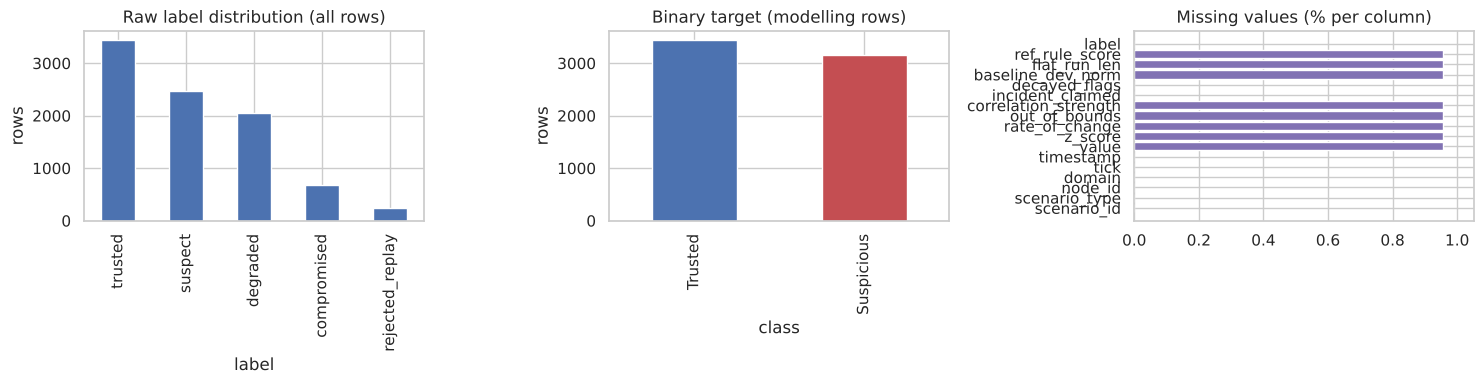

In [7]:
# --- Class distribution + missing values ---
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df[TARGET_COL].value_counts().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Raw label distribution (all rows)"); ax[0].set_ylabel("rows")
df_bin["class"].value_counts().plot.bar(ax=ax[1], color=["#4C72B0", "#C44E52"])
ax[1].set_title("Binary target (modelling rows)"); ax[1].set_ylabel("rows")
miss = df.isna().mean().mul(100)
ax[2].barh(miss.index, miss.values, color="#8172B3")
ax[2].set_title("Missing values (% per column)"); ax[2].set_xlim(0, max(1, miss.max() * 1.1))
plt.tight_layout(); plt.show()

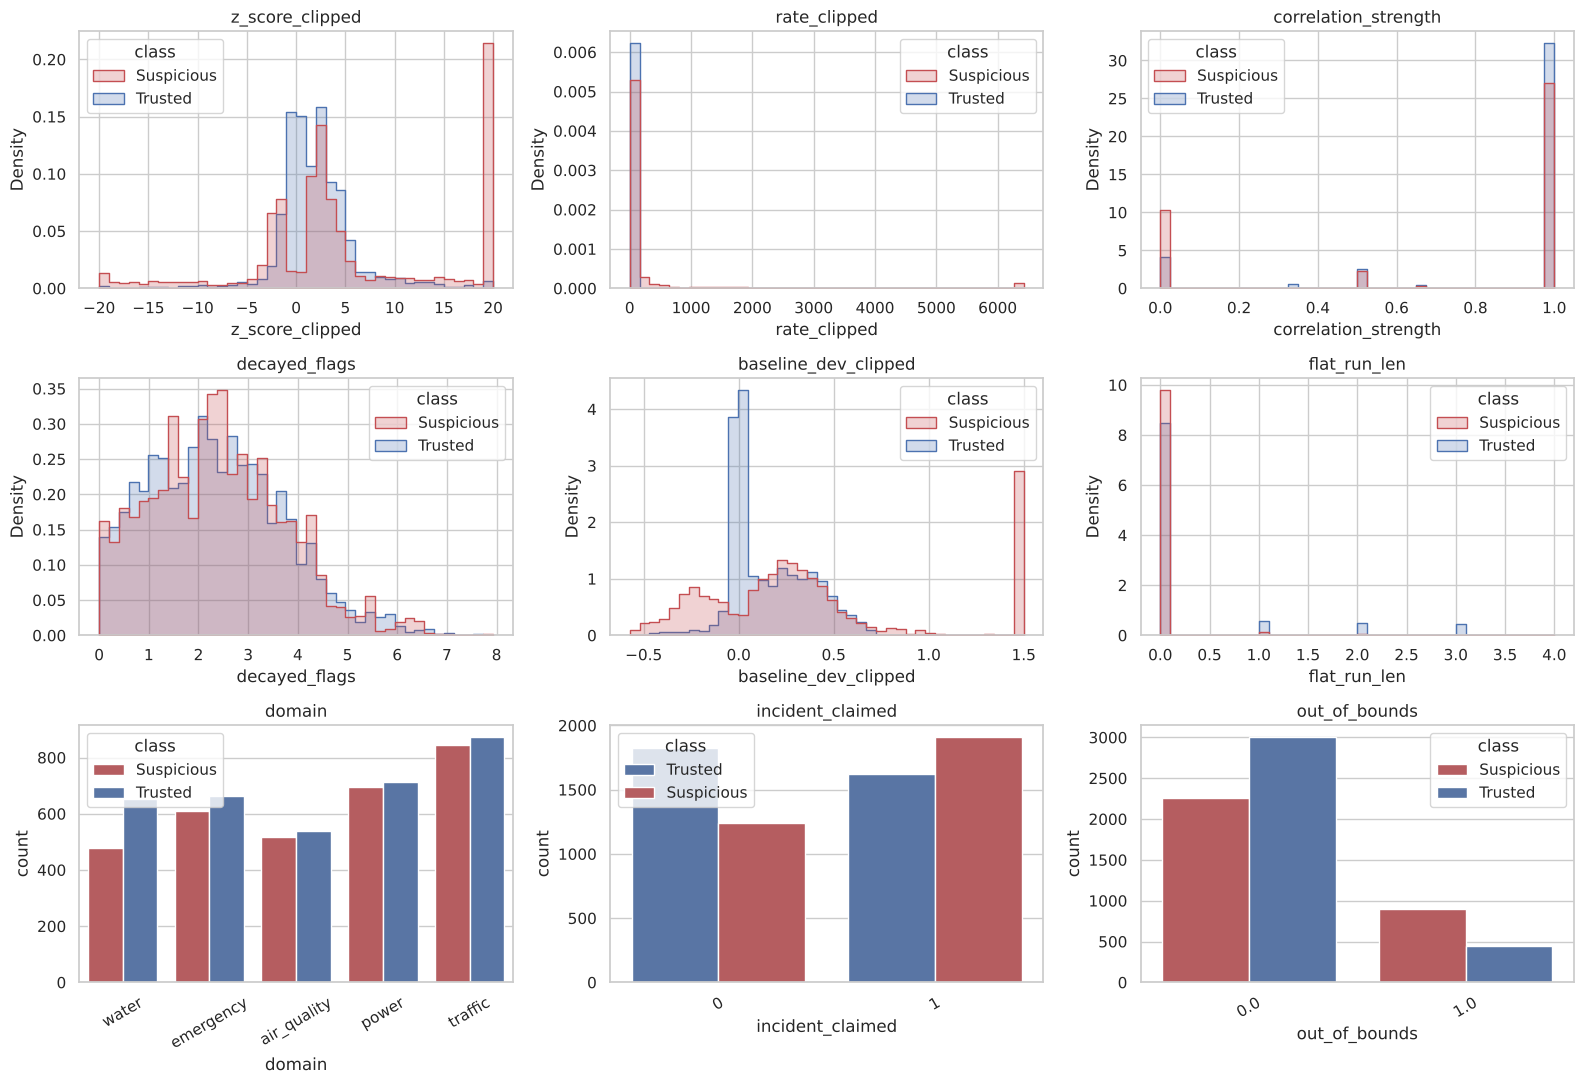

In [8]:
# --- Histograms of the numeric features by class ---
# z_score, rate and baseline deviation have heavy tails; clipped for display only (the model sees raw values).
pal = {"Trusted": "#4C72B0", "Suspicious": "#C44E52"}
plot_df = df_bin.assign(
    z_score_clipped=df_bin["z_score"].clip(-20, 20),
    rate_clipped=df_bin["rate_of_change"].clip(upper=df_bin["rate_of_change"].quantile(0.99)),
    baseline_dev_clipped=df_bin["baseline_dev_norm"].clip(-1.5, 1.5))
hist_feats = ["z_score_clipped", "rate_clipped", "correlation_strength",
              "decayed_flags", "baseline_dev_clipped", "flat_run_len"]
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
flat = axes.ravel()
for a, f in zip(flat[:6], hist_feats):
    sns.histplot(data=plot_df, x=f, hue="class", bins=40, stat="density", common_norm=False,
                 element="step", ax=a, palette=pal)
    a.set_title(f)
for a, f in zip(flat[6:], ["domain", "incident_claimed", "out_of_bounds"]):
    sns.countplot(data=df_bin, x=f, hue="class", ax=a, palette=pal)
    a.set_title(f); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

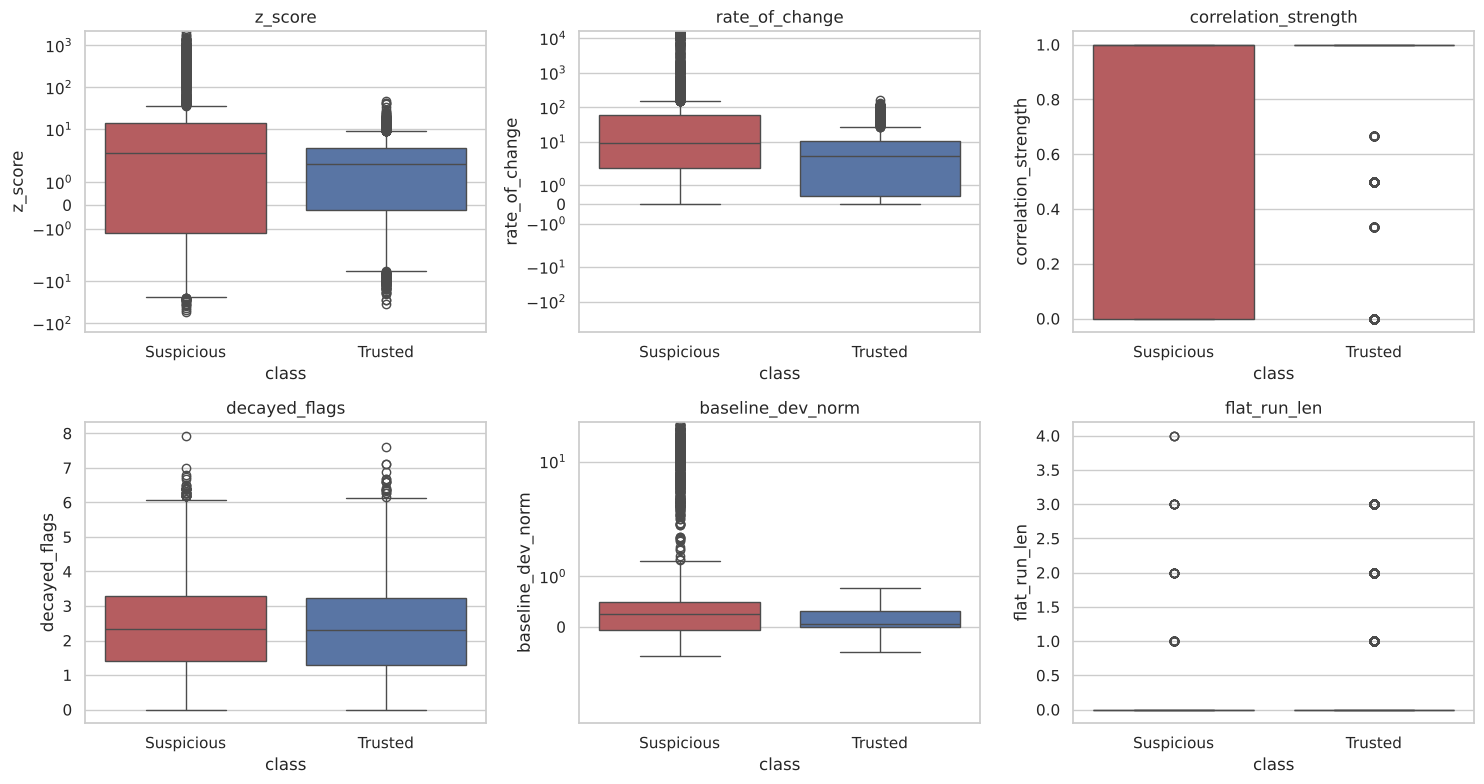

In [9]:
# --- Box plots by class (symlog axes because of heavy tails) ---
box_feats = ["z_score", "rate_of_change", "correlation_strength", "decayed_flags", "baseline_dev_norm", "flat_run_len"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, f in zip(axes.ravel(), box_feats):
    sns.boxplot(data=df_bin, x="class", y=f, hue="class", ax=a, legend=False, palette=pal)
    if f in ("z_score", "rate_of_change", "baseline_dev_norm"):
        a.set_yscale("symlog")
    a.set_title(f)
plt.tight_layout(); plt.show()

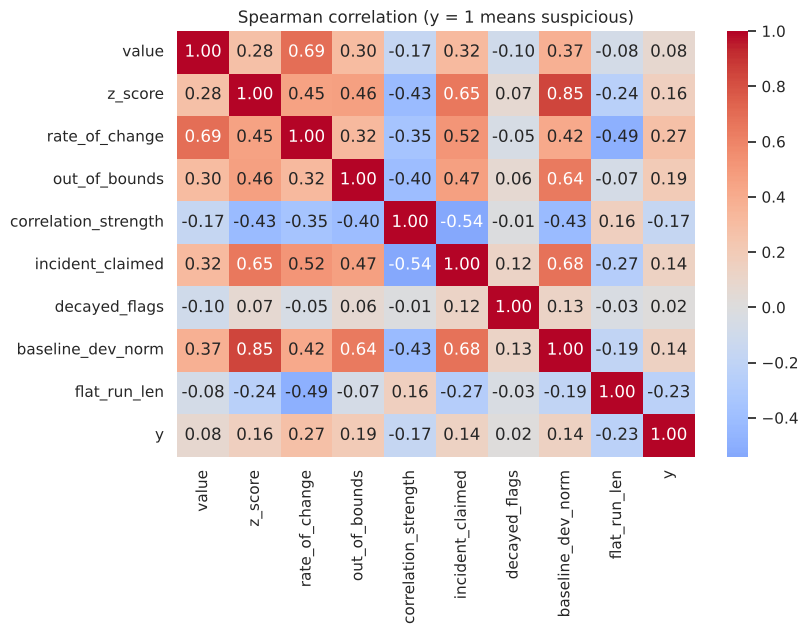

In [10]:
# --- Correlation heatmap (Spearman; robust to the heavy tails) ---
num_cols = ["value", "z_score", "rate_of_change", "out_of_bounds", "correlation_strength", "incident_claimed",
            "decayed_flags", "baseline_dev_norm", "flat_run_len", "y"]
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(df_bin[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation (y = 1 means suspicious)")
plt.tight_layout(); plt.show()

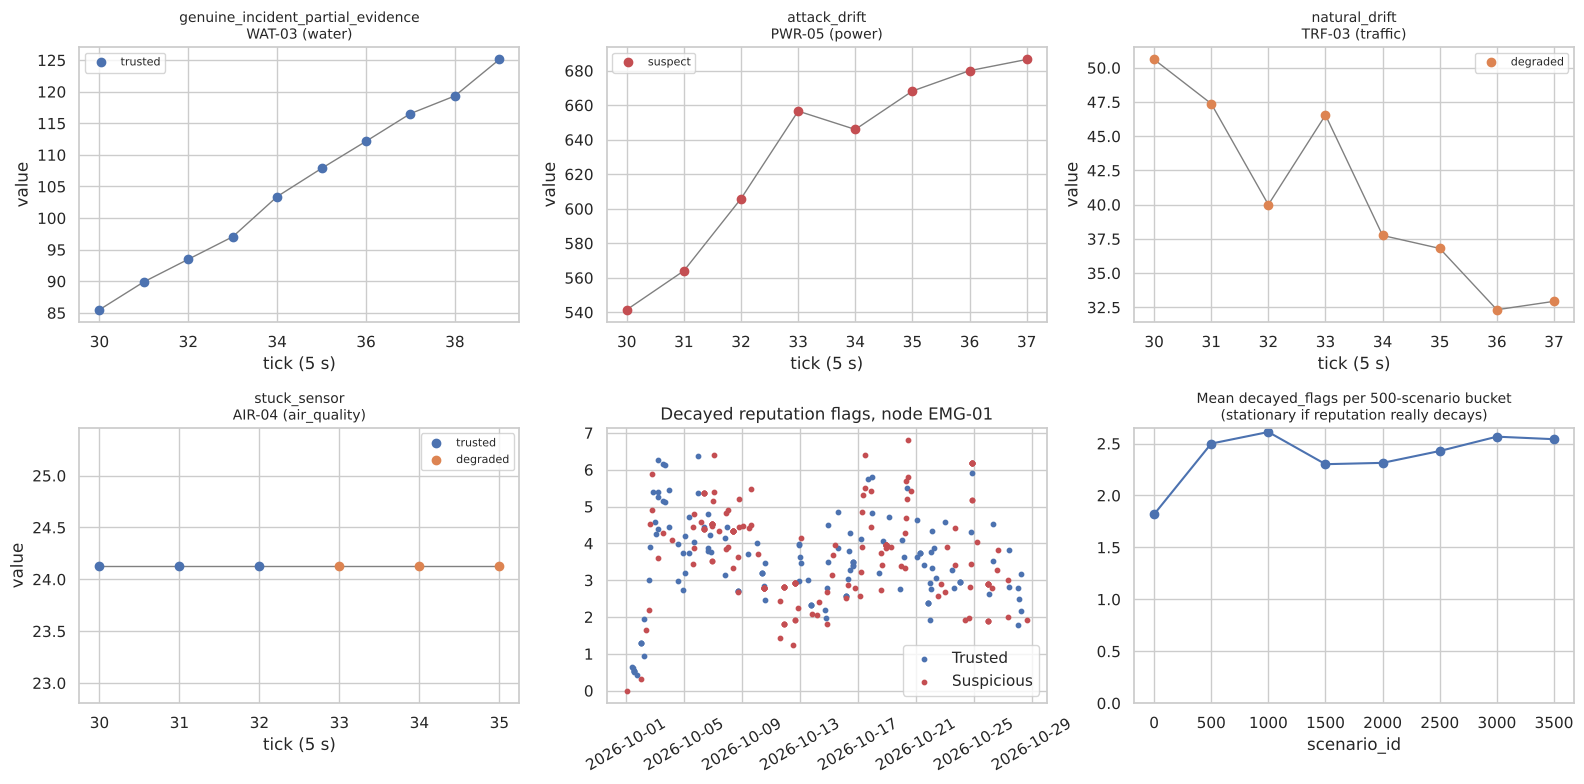

                                   z_score  rate_of_change  out_of_bounds  correlation_strength  incident_claimed  decayed_flags  baseline_dev_norm
scenario_type                                                                                                                                      
attack_drift                        -0.102           6.811          0.000                 1.000             0.000          2.423             -0.004
benign_spike                        -0.103          21.843          0.000                 1.000             0.000          2.067             -0.010
genuine_incident_full_evidence       4.369          23.461          0.287                 0.888             1.000          2.706              0.333
genuine_incident_partial_evidence    4.310          24.916          0.254                 0.447             1.000          2.643              0.325
normal                               0.028           6.035          0.000                 1.000             0.00

In [11]:
# --- Time series. Rows carry a simulated UTC timestamp and a per-scenario tick (5 s per tick). ---
def first_scenario_with(stype, min_rows=5):
    sizes = df[df["scenario_type"] == stype].groupby("scenario_id").size()
    return int(sizes[sizes >= min_rows].index[0])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, stype in zip(axes.ravel()[:4], ["genuine_incident_partial_evidence", "attack_drift", "natural_drift", "stuck_sensor"]):
    sub = df[df["scenario_id"] == first_scenario_with(stype)]
    a.plot(sub["tick"], sub["value"], color="grey", lw=1)
    for lab, col in [("trusted", "#4C72B0"), ("suspect", "#C44E52"), ("compromised", "#C44E52"), ("degraded", "#DD8452")]:
        m = sub[TARGET_COL] == lab
        if m.any():
            a.scatter(sub.loc[m, "tick"], sub.loc[m, "value"], color=col, label=lab, zorder=3)
    a.set_title(f"{stype}\n{sub['node_id'].iloc[0]} ({sub['domain'].iloc[0]})", fontsize=10)
    a.set_xlabel("tick (5 s)"); a.set_ylabel("value"); a.legend(fontsize=8)

busiest = df_bin["node_id"].value_counts().index[0]
sub = df_bin[df_bin["node_id"] == busiest].assign(ts=lambda d: pd.to_datetime(d["timestamp"]))
for cls, col in [("Trusted", "#4C72B0"), ("Suspicious", "#C44E52")]:
    m = sub["class"] == cls
    axes[1, 1].scatter(sub.loc[m, "ts"], sub.loc[m, "decayed_flags"], s=10, color=col, label=cls)
axes[1, 1].set_title(f"Decayed reputation flags, node {busiest}"); axes[1, 1].tick_params(axis="x", rotation=30); axes[1, 1].legend()

bucket = df_bin.assign(bucket=df_bin["scenario_id"] // 500).groupby("bucket")["decayed_flags"].mean()
axes[1, 2].plot(bucket.index * 500, bucket.values, marker="o")
axes[1, 2].set_title("Mean decayed_flags per 500-scenario bucket\n(stationary if reputation really decays)", fontsize=10)
axes[1, 2].set_xlabel("scenario_id"); axes[1, 2].set_ylim(bottom=0)
plt.tight_layout(); plt.show()

print(df_bin.groupby("scenario_type")[["z_score", "rate_of_change", "out_of_bounds", "correlation_strength",
                                       "incident_claimed", "decayed_flags", "baseline_dev_norm"]].mean().round(3).to_string())

### What the EDA does and does not show
- Suspicious is the minority class, so accuracy alone is misleading; precision/recall and PR curves are used.
- The per-scenario table above shows the structure the generator built in: genuine incidents are often **weakly corroborated** and sometimes **out of bounds**, while in-range spoofs have no out-of-bounds flag and (when un-corroborated) look like a genuine incident without evidence. These overlaps are deliberate — they are what makes this version harder than v1.
- The time-series panels show one example of each pattern: a genuine incident ramps up gradually, an attack drift stays in range, natural drift is milder, and a stuck sensor is perfectly flat.
- `decayed_flags` is built from a simple rule scorer's *non-trusted verdicts* (not from ground truth) with an 80-scenario half-life; the bucket plot should be roughly flat, i.e. no systematic drift across the timeline.
- `tick` has no information beyond position inside a scenario; it and `timestamp` are excluded from the model.
- Nothing here says how real attackers behave.

## 5. Preprocessing and feature engineering

Feature engineering lives in a small importable module, **`models/guardian_rf_features.py`**, written by the next cell. It must be importable (not defined inside the notebook) so the pickled pipeline can be reloaded in another process. It reads per-domain ranges and maximum rates from **`models/sensor_config.json`** (copied from `data/sensor_config.json`) instead of hard-coding them — in a real deployment this file should come from the Twin's capabilities.

| Model feature | Origin | Definition / rationale |
|---|---|---|
| `value_norm` | derived | `(value − lo) / (hi − lo)` with the domain's normal range from the config → comparable across domains (0–1 = normal range) |
| `z_score` | given | deviation from the last 6 readings of the node (Layer B); past readings only |
| `rate_norm` | derived | `rate_of_change / max_rate[domain]` — change per tick relative to the plausible maximum |
| `out_of_bounds` | given | 1 if the value is outside the normal range (Layer B) |
| `correlation_strength` | given | share of expected corroborating neighbour domains with evidence (Layer C); only meaningful when the reading claims an incident (1.0 otherwise, by convention) |
| `incident_claimed` | given | 1 if the reading is tagged with an incident type, which is when Layer C applies |
| `decayed_flags` | given | time-decayed count of earlier non-trusted verdicts for the node (Layer E), **before** the current reading |
| `baseline_dev_norm` | given | `(value − median of last 30 past readings) / range` — catches slow drift that the short z-score window absorbs |
| `flat_run_len` | given | number of immediately preceding readings identical to this one — catches stuck sensors |
| `domain` | given | one-hot encoded; unknown domains are handled safely |

**Missing values.** A dropped reading is a JSON `null` (never zero). Such rows are excluded from training (`degraded`), and the inference function abstains on them.

**Excluded on purpose:** `node_id` (identifier → memorisation), `scenario_id`, `tick`, `timestamp` (position, not behaviour), `scenario_type` (encodes the label), the label itself, and `ref_rule_score` (a rules-baseline output, used only for comparison).

**Leakage notes.** All history-based features are computed from earlier readings only. Unlike v1, the label is **not** a function of the model's inputs: it records whether the generator forged the reading, so `out_of_bounds` and `correlation_strength` are evidence that can be wrong in both directions. The caveat that remains is that the generator's attacker model is invented (Section 14).

In [12]:
FEATURE_MODULE = MODEL_DIR / "guardian_rf_features.py"
shutil.copy(SENSOR_CONFIG_PATH, MODEL_DIR / "sensor_config.json")   # the module reads its ranges from here
FEATURE_MODULE.write_text("""# Feature engineering for the Guardian Random Forest demo.
#
# Kept in its own module so a pickled pipeline can be reloaded in any process
# (put this folder on PYTHONPATH). Pure functions apart from reading sensor_config.json
# next to this file. No secrets.
import json
from pathlib import Path

import pandas as pd

CONFIG_PATH = Path(__file__).with_name("sensor_config.json")
_DOMAINS = json.loads(CONFIG_PATH.read_text())["domains"]
NORMAL_RANGES = {d: (c["lo"], c["hi"]) for d, c in _DOMAINS.items()}   # per-domain normal range
MAX_RATE = {d: c["max_rate"] for d, c in _DOMAINS.items()}             # max plausible change per tick
UNITS = {d: c["unit"] for d, c in _DOMAINS.items()}

RAW_INPUT_COLUMNS = ["domain", "value", "z_score", "rate_of_change", "out_of_bounds",
                     "correlation_strength", "incident_claimed", "decayed_flags",
                     "baseline_dev_norm", "flat_run_len"]
NUMERIC_FEATURES = ["value_norm", "z_score", "rate_norm", "out_of_bounds", "correlation_strength",
                    "incident_claimed", "decayed_flags", "baseline_dev_norm", "flat_run_len"]
CATEGORICAL_FEATURES = ["domain"]


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    missing = [c for c in RAW_INPUT_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing input columns: {missing}")
    lo = df["domain"].map({k: v[0] for k, v in NORMAL_RANGES.items()})
    hi = df["domain"].map({k: v[1] for k, v in NORMAL_RANGES.items()})
    max_rate = df["domain"].map(MAX_RATE)
    num = lambda c: pd.to_numeric(df[c])
    out = pd.DataFrame(index=df.index)
    out["value_norm"] = (num("value") - lo) / (hi - lo)       # NaN for unknown domain or missing value
    out["z_score"] = num("z_score")
    out["rate_norm"] = num("rate_of_change") / max_rate
    out["out_of_bounds"] = num("out_of_bounds")
    out["correlation_strength"] = num("correlation_strength")
    out["incident_claimed"] = num("incident_claimed")
    out["decayed_flags"] = num("decayed_flags")
    out["baseline_dev_norm"] = num("baseline_dev_norm")
    out["flat_run_len"] = num("flat_run_len")
    out["domain"] = df["domain"].astype(object)
    return out[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
""")

if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
import guardian_rf_features as grf
importlib.reload(grf)

# Sanity check: all domains in the data are known to the feature module
unknown_domains = set(df_bin["domain"]) - set(grf.NORMAL_RANGES)
assert not unknown_domains, f"Unknown domains {unknown_domains}: add them to {SENSOR_CONFIG_PATH}"

display(grf.engineer_features(df_bin[grf.RAW_INPUT_COLUMNS]).head())


def make_preprocessor() -> ColumnTransformer:
    # Everything below is fitted on TRAINING data only, inside the pipeline.
    numeric = Pipeline([("impute", SimpleImputer(strategy="median"))])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric, grf.NUMERIC_FEATURES),
                              ("cat", categorical, grf.CATEGORICAL_FEATURES)])


def make_pipeline(classifier) -> Pipeline:
    return Pipeline([("features", FunctionTransformer(grf.engineer_features, validate=False)),
                     ("prep", make_preprocessor()),
                     ("clf", classifier)])

,value_norm,z_score,rate_norm,out_of_bounds,correlation_strength,incident_claimed,decayed_flags,baseline_dev_norm,flat_run_len,domain
0,0.307210,-13.028,5.311833,0.0,0.0,1,0.0,-0.3401,0.0,water
1,0.361000,0.549,0.010667,0.0,1.0,0,0.0,0.0385,0.0,emergency
2,1.309160,35.818,13.055000,1.0,0.0,1,0.0,0.8228,0.0,water
3,0.293267,-1.152,0.149167,0.0,1.0,0,0.0,-0.0127,0.0,air_quality
4,0.000000,-7.999,0.768667,0.0,1.0,0,0.0,-0.2709,0.0,air_quality


## 6. Train / validation / test split

**Strategy: chronological split on scenario boundaries.**

- Device reputation (`decayed_flags`) is a running history along `scenario_id`, so a random shuffle would let the model train on "future" reputation states. We therefore split by **generation order**: first 60 % of scenarios → train, next 20 % → validation, last 20 % → test.
- Splitting on *scenario* boundaries (never inside a scenario) also acts as the group split: multi-row scenarios (incident ramps, attack drift, stuck sensor) cannot straddle two sets — rows of one ramp are strongly dependent, so splitting inside a scenario would inflate the scores.
- **Validation** is used for threshold selection and model choice. **Test** is used once for final reporting.

Because reputation now decays, the three periods should look statistically alike (compare `mean_decayed_flags` below); a real deployment would still face seasonal and attacker-behaviour shift that a single chronological split cannot reveal.

In [13]:
scenario_ids = np.sort(df_bin["scenario_id"].unique())
n_sc = len(scenario_ids)
train_ids = scenario_ids[: int(TRAIN_FRAC * n_sc)]
val_ids = scenario_ids[int(TRAIN_FRAC * n_sc): int((TRAIN_FRAC + VAL_FRAC) * n_sc)]
test_ids = scenario_ids[int((TRAIN_FRAC + VAL_FRAC) * n_sc):]

assert not (set(train_ids) & set(val_ids)) and not (set(val_ids) & set(test_ids)) and not (set(train_ids) & set(test_ids))
assert train_ids.max() < val_ids.min() and val_ids.max() < test_ids.min(), "split is not chronological"

train_df = df_bin[df_bin["scenario_id"].isin(train_ids)]
val_df = df_bin[df_bin["scenario_id"].isin(val_ids)]
test_df = df_bin[df_bin["scenario_id"].isin(test_ids)]

X_train, y_train = train_df[grf.RAW_INPUT_COLUMNS], train_df["y"].to_numpy()
X_val, y_val = val_df[grf.RAW_INPUT_COLUMNS], val_df["y"].to_numpy()
X_test, y_test = test_df[grf.RAW_INPUT_COLUMNS], test_df["y"].to_numpy()

summary = pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "suspicious": [y_train.sum(), y_val.sum(), y_test.sum()],
    "suspicious_share": [y_train.mean(), y_val.mean(), y_test.mean()],
    "scenario_range": [f"{train_ids.min()}-{train_ids.max()}", f"{val_ids.min()}-{val_ids.max()}",
                       f"{test_ids.min()}-{test_ids.max()}"],
    "mean_decayed_flags": [train_df.decayed_flags.mean(), val_df.decayed_flags.mean(), test_df.decayed_flags.mean()],
}, index=["train", "validation", "test"]).round(3)
display(summary)

for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    assert len(np.unique(y)) == 2, f"{name} split has a single class; metrics such as ROC-AUC would be undefined"

,rows,suspicious,suspicious_share,scenario_range,mean_decayed_flags
train,3989,1925,0.483,0-2390,2.294
validation,1282,616,0.480,2391-3195,2.530
test,1318,607,0.461,3196-3999,2.493


## 7. Random Forest baseline

`RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=3)`:
- 300 trees give stable probabilities at this data size.
- `class_weight` compensates for the minority suspicious class without resampling the data.
- `min_samples_leaf=3` stops single-row leaves, giving smoother probabilities (useful because we threshold them later).

Three reference points establish whether the forest adds value:
1. **Dummy** (always predicts the majority class) — the "do nothing" floor.
2. **Depth-2 decision tree** — how far a trivially simple, human-readable model already gets.
3. **Reference rules** — the penalty table from the Guardian technical report (out of bounds −0.50, rate −0.35, z-score −0.25, no/weak corroboration −0.45/−0.20, prior flags up to −0.25; "not trusted" when score ≤ 0.7), re-implemented in the generator as `ref_rule_score`. **This is my reading of the report, not your real `scoring.py`;** the z-score (|z|>3) and rate thresholds are assumptions. Treat it as an indicative baseline until the real scorer is run on the same data.

In [14]:
dummy = make_pipeline(DummyClassifier(strategy="prior")).fit(X_train, y_train)
stump = make_pipeline(DecisionTreeClassifier(max_depth=2, class_weight="balanced",
                                             random_state=RANDOM_STATE)).fit(X_train, y_train)
rf_base = make_pipeline(RandomForestClassifier(
    n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=3,
    n_jobs=-1, random_state=RANDOM_STATE)).fit(X_train, y_train)

for name, m in [("dummy", dummy), ("depth-2 tree", stump), ("random forest", rf_base)]:
    print(f"{name:14s} trained; classes={m.named_steps['clf'].classes_.tolist()}")

dummy          trained; classes=[0, 1]
depth-2 tree   trained; classes=[0, 1]
random forest  trained; classes=[0, 1]


## 8. Model evaluation

**Positive class = Suspicious.**

- *False positive* = a trustworthy reading flagged as suspicious → needless alerts, wasted operator time, possibly good data discarded.
- *False negative* = a suspicious reading passed as trustworthy → a spoofed value may reach City Brain.

For security the false negative is usually costlier, but an alarm stream with too many false positives gets ignored, so we fix an explicit budget instead of using the default 0.5 cut-off: **the highest recall achievable with validation FPR ≤ 5 %** (configurable). The threshold is chosen on the **validation** set only.

Metrics that need both classes (ROC-AUC, average precision) are reported as `NaN` with a note when a split contains a single class.

In [15]:
def proba_suspicious(model, X) -> np.ndarray:
    classes = list(model.named_steps["clf"].classes_)
    return model.predict_proba(X)[:, classes.index(1)]


def evaluate(y_true, proba, threshold: float) -> dict:
    y_true = np.asarray(y_true)
    y_pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    if not both:
        print("NOTE: only one class present -> ROC-AUC / average precision are undefined (NaN).")
    return {
        "threshold": round(float(threshold), 4),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba) if both else np.nan,
        "avg_precision": average_precision_score(y_true, proba) if both else np.nan,
        "fpr": fp / (fp + tn) if (fp + tn) else np.nan,
        "fnr": fn / (fn + tp) if (fn + tp) else np.nan,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }


def choose_threshold(y_true, proba, max_fpr: float = MAX_VALIDATION_FPR) -> float:
    """Highest recall with FPR <= max_fpr on the given (validation) data; ties -> highest threshold."""
    fpr, tpr, thr = roc_curve(y_true, proba)
    ok = (fpr <= max_fpr) & np.isfinite(thr)
    if not ok.any():
        print("WARNING: no finite threshold satisfies the FPR budget; falling back to 0.5")
        return 0.5
    best_tpr = tpr[ok].max()
    return float(thr[ok & (tpr == best_tpr)].max())


# Validation-only decisions for each model
val_proba = {n: proba_suspicious(m, X_val) for n, m in
             [("dummy", dummy), ("depth-2 tree", stump), ("random forest", rf_base)]}
thresholds = {"dummy": 0.5,  # constant prior probability -> a data-derived threshold is meaningless
              "depth-2 tree": choose_threshold(y_val, val_proba["depth-2 tree"]),
              "random forest": choose_threshold(y_val, val_proba["random forest"])}

if REFERENCE_SCORE_COL in df_bin.columns:
    val_proba["reference rules"] = (1 - val_df[REFERENCE_SCORE_COL]).to_numpy()    # higher = more suspicious
    thresholds["reference rules"] = 0.3 - 1e-9                                     # score <= 0.7  <=>  not "trusted"

val_table = pd.DataFrame({n: evaluate(y_val, val_proba[n], thresholds[n]) for n in val_proba}).T
print("VALIDATION metrics (thresholds selected here):")
display(val_table.round(4))

VALIDATION metrics (thresholds selected here):


,threshold,accuracy,precision,recall,f1,roc_auc,avg_precision,fpr,fnr,TP,FP,FN,TN
dummy,0.5000,0.5195,0.0000,0.0000,0.0000,0.5000,0.4805,0.0000,1.0000,0.0,0.0,616.0,666.0
depth-2 tree,0.8568,0.7137,0.9164,0.4448,0.5989,0.7296,0.7192,0.0375,0.5552,274.0,25.0,342.0,641.0
random forest,0.5660,0.8034,0.9233,0.6445,0.7591,0.8680,0.8906,0.0495,0.3555,397.0,33.0,219.0,633.0
reference rules,0.3000,0.5835,0.5542,0.6802,0.6108,0.6460,0.6452,0.5060,0.3198,419.0,337.0,197.0,329.0


In [16]:
# Final one-time look at the TEST set for the baseline-stage models (no decisions are taken from it).
test_proba = {n: proba_suspicious(m, X_test) for n, m in
              [("dummy", dummy), ("depth-2 tree", stump), ("random forest", rf_base)]}
if "reference rules" in val_proba:
    test_proba["reference rules"] = (1 - test_df[REFERENCE_SCORE_COL]).to_numpy()
test_table = pd.DataFrame({n: evaluate(y_test, test_proba[n], thresholds[n]) for n in test_proba}).T
print("TEST metrics (thresholds fixed from validation):")
display(test_table.round(4))

print("\nClassification report - random forest, test, tuned threshold:")
pred = (test_proba["random forest"] >= thresholds["random forest"]).astype(int)
print(classification_report(y_test, pred, target_names=["Trusted", "Suspicious"], zero_division=0))

TEST metrics (thresholds fixed from validation):


,threshold,accuracy,precision,recall,f1,roc_auc,avg_precision,fpr,fnr,TP,FP,FN,TN
dummy,0.5000,0.5395,0.0000,0.0000,0.0000,0.5000,0.4605,0.0000,1.0000,0.0,0.0,607.0,711.0
depth-2 tree,0.8568,0.7375,0.9169,0.4728,0.6239,0.7391,0.7204,0.0366,0.5272,287.0,26.0,320.0,685.0
random forest,0.5660,0.8361,0.9064,0.7183,0.8015,0.8960,0.9097,0.0633,0.2817,436.0,45.0,171.0,666.0
reference rules,0.3000,0.5933,0.5492,0.6524,0.5964,0.6668,0.6476,0.4571,0.3476,396.0,325.0,211.0,386.0



Classification report - random forest, test, tuned threshold:
              precision    recall  f1-score   support

     Trusted       0.80      0.94      0.86       711
  Suspicious       0.91      0.72      0.80       607

    accuracy                           0.84      1318
   macro avg       0.85      0.83      0.83      1318
weighted avg       0.85      0.84      0.83      1318



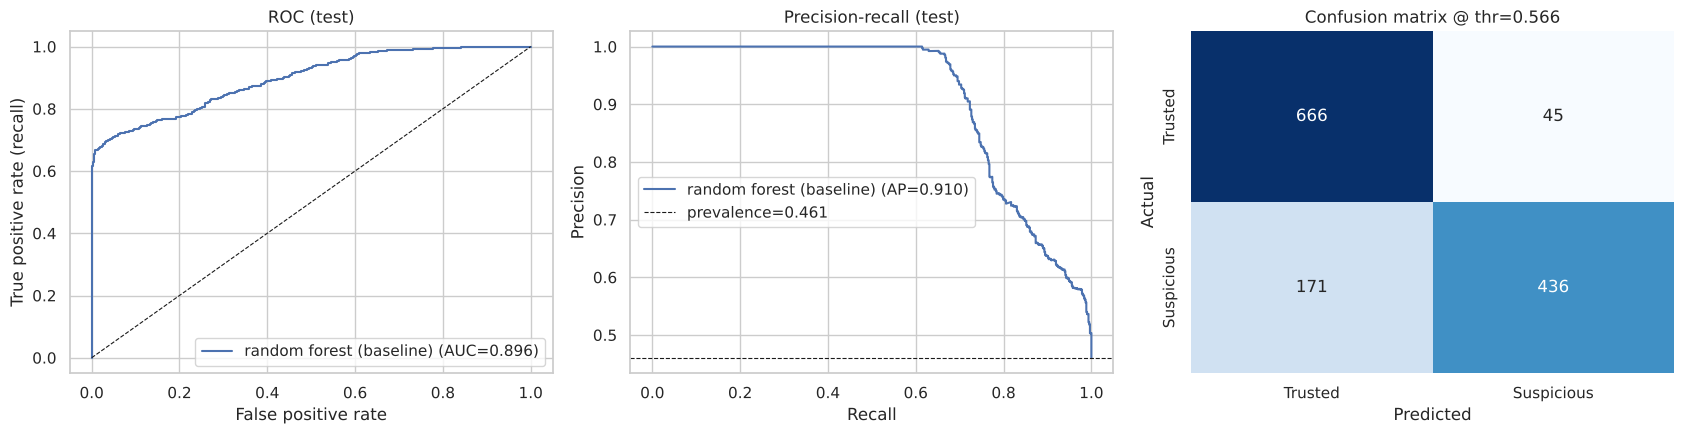

In [17]:
def plot_curves(model_name, y_true, proba, thr, axes):
    fpr, tpr, _ = roc_curve(y_true, proba)
    axes[0].plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc_score(y_true, proba):.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
    axes[0].set_title("ROC (test)"); axes[0].legend()
    p, r, _ = precision_recall_curve(y_true, proba)
    axes[1].plot(r, p, label=f"{model_name} (AP={average_precision_score(y_true, proba):.3f})")
    axes[1].axhline(np.mean(y_true), color="k", ls="--", lw=0.8, label=f"prevalence={np.mean(y_true):.3f}")
    axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall (test)")
    axes[1].legend()
    cm = confusion_matrix(y_true, (proba >= thr).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
                xticklabels=["Trusted", "Suspicious"], yticklabels=["Trusted", "Suspicious"])
    axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Actual"); axes[2].set_title(f"Confusion matrix @ thr={thr:.3f}")


fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_curves("random forest (baseline)", y_test, test_proba["random forest"], thresholds["random forest"], axes)
plt.tight_layout(); plt.show()

In [18]:
# Where does the model struggle? Behaviour per scenario type on TEST (share of rows flagged as suspicious).
tt = test_df.assign(rf_flagged=(test_proba["random forest"] >= thresholds["random forest"]).astype(int))
agg = {"rows": ("y", "size"), "truly_suspicious": ("y", "mean"), "rf_flagged": ("rf_flagged", "mean")}
if "reference rules" in test_proba:
    tt["rules_flagged"] = (test_proba["reference rules"] >= thresholds["reference rules"]).astype(int)
    agg["rules_flagged"] = ("rules_flagged", "mean")
by_type = tt.groupby("scenario_type").agg(**agg).round(3)
display(by_type)
print("For truly_suspicious = 1 rows, the flagged share is recall; for 0 rows it is the false-positive rate.")

mask = (X_test["out_of_bounds"] == 0).to_numpy()
print(f"\nTest rows inside normal bounds: {mask.sum()}  (suspicious among them: {int(y_test[mask].sum())})")
if len(np.unique(y_test[mask])) == 2:
    display(pd.Series(evaluate(y_test[mask], test_proba["random forest"][mask], thresholds["random forest"])).round(4).to_frame("in-bounds subset"))
else:
    print("Only one class among in-bounds rows -> ROC-AUC / AP undefined for this subset.")

# Excluded classes: NOT trained on. How does the model score them? (informational only)
ex = df_excluded[df_excluded["scenario_id"] > val_ids.max()]   # same time period as the test split
ex_scored = ex[ex["value"].notna()]
print(f"\nExcluded rows in the test period: {len(ex)} ({len(ex) - len(ex_scored)} sensor dropouts: value is null -> the model abstains)")
if len(ex_scored):
    ex_flag = pd.Series((proba_suspicious(rf_base, ex_scored[grf.RAW_INPUT_COLUMNS]) >= thresholds["random forest"]), index=ex_scored.index)
    display(ex_flag.groupby([ex_scored["scenario_type"], ex_scored[TARGET_COL]]).agg(rows="size", flagged_share="mean").round(3))
    print("Natural drift / stuck sensors are sensor-health problems, not attacks; replay carries ordinary-looking numbers and\\n"
          "MUST be caught by Layer A (sequence/nonce checks), never by this model.")

,rows,truly_suspicious,rf_flagged,rules_flagged
scenario_type,,,,
attack_drift,240,1.0,0.842,0.208
benign_spike,47,0.0,0.106,0.638
genuine_incident_full_evidence,180,0.0,0.122,0.772
genuine_incident_partial_evidence,154,0.0,0.058,0.909
normal,213,0.0,0.028,0.075
spoofed_coordinated,49,1.0,1.000,1.000
spoofed_in_range,66,1.0,0.879,0.985
spoofed_in_range_corroborated,41,1.0,0.878,1.000
spoofed_isolated,85,1.0,0.988,1.000


For truly_suspicious = 1 rows, the flagged share is recall; for 0 rows it is the false-positive rate.

Test rows inside normal bounds: 1037  (suspicious among them: 432)


,in-bounds subset
threshold,0.5660
accuracy,0.8419
precision,0.9012
recall,0.6968
f1,0.7859
roc_auc,0.8991
avg_precision,0.8973
fpr,0.0545
fnr,0.3032
TP,301.0000



Excluded rows in the test period: 489 (19 sensor dropouts: value is null -> the model abstains)


,,rows,flagged_share
scenario_type,label,,
natural_drift,degraded,304,0.579
replay_exact,rejected_replay,49,0.000
stuck_sensor,degraded,117,0.026


Natural drift / stuck sensors are sensor-health problems, not attacks; replay carries ordinary-looking numbers and\nMUST be caught by Layer A (sequence/nonce checks), never by this model.


### Reading these results honestly
*(Numbers quoted are from the shipped run, seed 42; they will move slightly with other library versions.)*

- **Accuracy is a weak guide.** Suspicious rows are ~46 % of the test set (the multi-row adaptive-ramp scenario emits many rows), so the dummy already gets ~54 %.
- **The operating point is a budget, not a truth.** Threshold 0.566 was chosen on validation for FPR ≤ 5 %; on test the FPR came out at 6.3 %, i.e. a validation-chosen threshold does not transfer perfectly. On test the forest reaches precision 0.91, recall 0.72, F1 0.80, average precision 0.91, against F1 0.62 for the depth-2 tree — so, unlike v1, the forest adds real value over a trivial model.
- **The per-scenario table is the real result.**
  - Blatant out-of-range spoofs: 99–100 % flagged. In-range spoofs (with or without corroboration): ~88 %. Slow in-range drift attack: ~84 %.
  - **The adaptive attacker — a gradual forged ramp *with* forged neighbour corroboration — is flagged only ~6 % of the time.** Numerically it tells the same story as a genuine, fully corroborated incident (which the model flags ~12 % of the time). No per-reading model on these features can separate the two; that case needs other evidence (Layer D command/effect checks, signatures, cross-sensor value consistency, long-horizon reputation).
- **Where the false alarms are:** genuine fully corroborated incidents (~12 %), benign in-range spikes (~11 %), and natural drift (~58 %, a sensor-health problem that would surface as a health alert rather than an attack).
- **The `reference rules` row is not Guardian's performance.** It is my re-implementation of the report's penalty table with *assumed* z-score and rate thresholds. It flags 77–91 % of genuine incidents and 64 % of benign spikes (FPR ≈ 46 %), which is almost certainly pessimistic compared with a tuned scorer. Its only purpose here is to give the comparison a slot: run your real `scoring.py` on the same data and replace the `ref_rule_score` column to get a meaningful baseline.

## 9. Hyperparameter tuning

- `RandomizedSearchCV` over forest size, depth, leaf size, feature subsampling and class weighting.
- **Scoring: average precision** (threshold-free, focuses on the suspicious class under imbalance).
- **Cross-validation respects time and scenarios:** expanding-window folds built on scenario boundaries (train on earlier scenarios, validate on the next block), applied to the *training* split only. Validation and test are never seen by the search.

In [19]:
def scenario_expanding_splits(scenario_id_array, n_splits: int):
    ids = np.sort(np.unique(scenario_id_array))
    blocks = np.array_split(ids, n_splits + 1)
    for k in range(1, n_splits + 1):
        tr = np.where(np.isin(scenario_id_array, np.concatenate(blocks[:k])))[0]
        te = np.where(np.isin(scenario_id_array, blocks[k]))[0]
        yield tr, te


cv_splits = list(scenario_expanding_splits(train_df["scenario_id"].to_numpy(), N_CV_SPLITS))
for i, (tr, te) in enumerate(cv_splits):
    assert len(np.unique(y_train[tr])) == 2 and len(np.unique(y_train[te])) == 2, f"fold {i} lacks a class"

param_distributions = {
    "clf__n_estimators": [200, 300, 500],
    "clf__max_depth": [None, 6, 10, 16],
    "clf__min_samples_leaf": [1, 2, 3, 5, 10],
    "clf__max_features": ["sqrt", 0.5, None],
    "clf__class_weight": ["balanced", "balanced_subsample", None],
}
search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions=param_distributions, n_iter=N_SEARCH_ITER, scoring="average_precision",
    cv=cv_splits, random_state=RANDOM_STATE, n_jobs=1, refit=True, error_score="raise")
search.fit(X_train, y_train)

print("best CV average precision:", round(search.best_score_, 4))
print("best params:", search.best_params_)
display(pd.DataFrame(search.cv_results_)[["mean_test_score", "std_test_score", "params"]]
        .sort_values("mean_test_score", ascending=False).head(5))

best CV average precision: 0.9062
best params: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 1, 'clf__max_features': None, 'clf__max_depth': 6, 'clf__class_weight': 'balanced'}


,mean_test_score,std_test_score,params
5,0.906219,0.013915,"{'clf__n_estimators': 500, 'clf__min_samples_l..."
4,0.905946,0.013605,"{'clf__n_estimators': 300, 'clf__min_samples_l..."
3,0.904953,0.013647,"{'clf__n_estimators': 500, 'clf__min_samples_l..."
11,0.903654,0.011639,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
6,0.903500,0.011649,"{'clf__n_estimators': 200, 'clf__min_samples_l..."


In [20]:
rf_tuned = search.best_estimator_
val_proba["random forest (tuned)"] = proba_suspicious(rf_tuned, X_val)
thresholds["random forest (tuned)"] = choose_threshold(y_val, val_proba["random forest (tuned)"])

cmp_val = pd.DataFrame({n: evaluate(y_val, val_proba[n], thresholds[n])
                        for n in ["random forest", "random forest (tuned)"]}).T
print("VALIDATION comparison (model choice is made here):")
display(cmp_val[["threshold", "precision", "recall", "f1", "roc_auc", "avg_precision", "fpr", "fnr"]].round(4))

# Choose the final model on VALIDATION average precision; keep the simpler baseline unless tuning gains a clear margin
# (cross-validation std is ~0.01, so smaller gains are noise).
ap_base, ap_tuned = cmp_val.loc["random forest", "avg_precision"], cmp_val.loc["random forest (tuned)", "avg_precision"]
if ap_tuned > ap_base + MIN_AP_GAIN_FOR_TUNING:
    FINAL_NAME, FINAL_MODEL = "random forest (tuned)", rf_tuned
else:
    FINAL_NAME, FINAL_MODEL = "random forest", rf_base
FINAL_THRESHOLD = thresholds[FINAL_NAME]
print(f"\nSelected on validation: {FINAL_NAME}  (val AP baseline={ap_base:.4f}, tuned={ap_tuned:.4f}); "
      f"threshold={FINAL_THRESHOLD:.4f}")

test_proba["random forest (tuned)"] = proba_suspicious(rf_tuned, X_test)
cmp_test = pd.DataFrame({n: evaluate(y_test, test_proba[n], thresholds[n])
                         for n in ["random forest", "random forest (tuned)"]}).T
print("\nTEST comparison (reporting only):")
display(cmp_test[["threshold", "precision", "recall", "f1", "roc_auc", "avg_precision", "fpr", "fnr"]].round(4))

VALIDATION comparison (model choice is made here):


,threshold,precision,recall,f1,roc_auc,avg_precision,fpr,fnr
random forest,0.5660,0.9233,0.6445,0.7591,0.8680,0.8906,0.0495,0.3555
random forest (tuned),0.5229,0.9244,0.5958,0.7246,0.8743,0.8893,0.0450,0.4042



Selected on validation: random forest  (val AP baseline=0.8906, tuned=0.8893); threshold=0.5660



TEST comparison (reporting only):


,threshold,precision,recall,f1,roc_auc,avg_precision,fpr,fnr
random forest,0.5660,0.9064,0.7183,0.8015,0.8960,0.9097,0.0633,0.2817
random forest (tuned),0.5229,0.9430,0.7084,0.8090,0.9023,0.9141,0.0366,0.2916


**Did tuning help?** Judge from the validation table, not the test table. In the shipped run validation average precision is 0.891 (baseline) vs 0.889 (tuned), well inside the cross-validation standard deviation (~0.014), so the rule keeps the simpler baseline (a gain below `MIN_AP_GAIN_FOR_TUNING` = 0.005 is treated as noise). The tuned model happens to look slightly better on test; that is not used for selection.

## 10. Feature importance and explainability

Two views:
- **Impurity importance** from the forest (fast, but biased toward high-cardinality / continuous features and computed on training data).
- **Permutation importance** on the held-out *validation* set, scored by average precision — how much the ranking quality degrades when a column is shuffled.

Importance measures *predictive contribution, not causation*: it says what the model uses, not what causes an attack.

Then a shortcut audit: retrain without individual features to see how much the model depends on any single one.

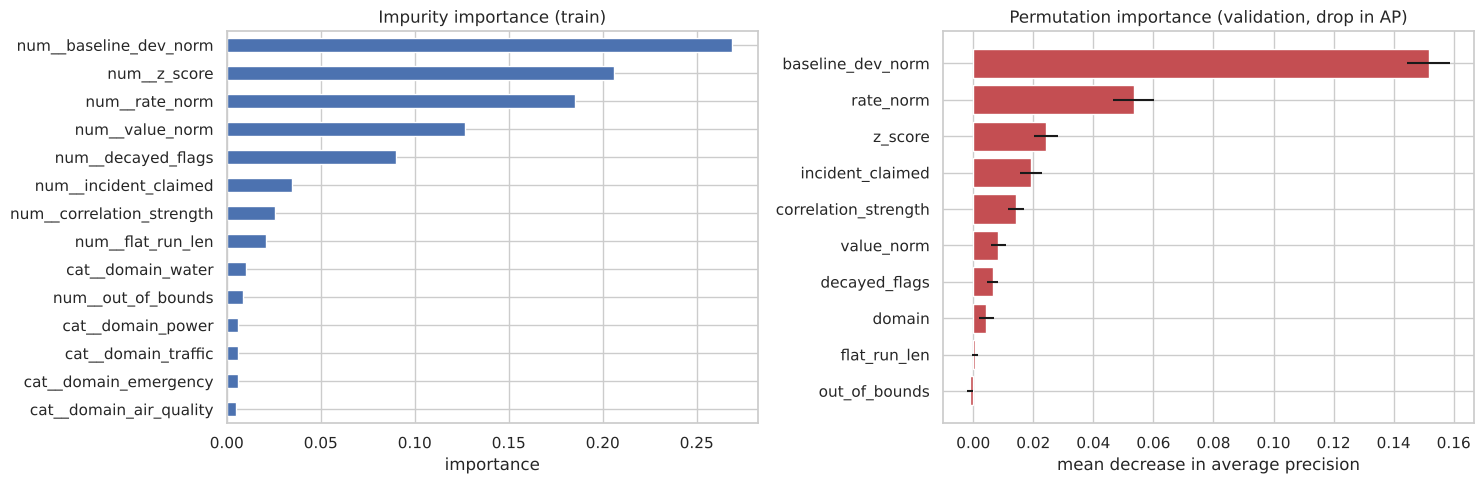

,num__baseline_dev_norm,num__z_score,num__rate_norm,num__value_norm,num__decayed_flags,num__incident_claimed,num__correlation_strength,num__flat_run_len,cat__domain_water,num__out_of_bounds,cat__domain_power,cat__domain_traffic,cat__domain_emergency,cat__domain_air_quality
impurity,0.269,0.2058,0.1852,0.127,0.0903,0.0347,0.0259,0.0206,0.0102,0.0087,0.006,0.0059,0.0059,0.0048


In [21]:
feature_names = FINAL_MODEL.named_steps["prep"].get_feature_names_out()
impurity = pd.Series(FINAL_MODEL.named_steps["clf"].feature_importances_, index=feature_names).sort_values(ascending=False)

# Permute the ENGINEERED features (not the raw columns): permuting raw `domain` would also corrupt the
# derived value_norm / rate_norm, which are computed from it, and overstate domain's importance.
inner_model = Pipeline(FINAL_MODEL.steps[1:])                       # prep + clf
X_val_eng = FINAL_MODEL.named_steps["features"].transform(X_val)    # engineered validation features
perm = permutation_importance(inner_model, X_val_eng, y_val, scoring="average_precision",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=X_val_eng.columns)
perm_err = pd.Series(perm.importances_std, index=X_val_eng.columns)
perm_s = perm_s.sort_values(ascending=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
impurity.sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Impurity importance (train)"); ax[0].set_xlabel("importance")
ax[1].barh(perm_s.index, perm_s.values, xerr=perm_err[perm_s.index].values, color="#C44E52")
ax[1].set_title("Permutation importance (validation, drop in AP)"); ax[1].set_xlabel("mean decrease in average precision")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"impurity": impurity.round(4)}).T)

In [22]:
# Shortcut audit: how much does validation AP fall if a feature (group) is removed and the model retrained?
RAW_TO_ENGINEERED = {"value": "value_norm", "rate_of_change": "rate_norm"}


def val_ap_without(drop_raw_cols):
    drop_eng = {RAW_TO_ENGINEERED.get(c, c) for c in drop_raw_cols}
    keep_num = [c for c in grf.NUMERIC_FEATURES if c not in drop_eng]
    keep_cat = [c for c in grf.CATEGORICAL_FEATURES if c not in drop_eng]

    def feats(d):
        return grf.engineer_features(d)[keep_num + keep_cat]

    transformers = [("num", SimpleImputer(strategy="median"), keep_num)]
    if keep_cat:
        transformers.append(("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                                              ("o", OneHotEncoder(handle_unknown="ignore"))]), keep_cat))
    prep = ColumnTransformer(transformers)
    params = {k.replace("clf__", ""): v for k, v in FINAL_MODEL.named_steps["clf"].get_params().items()
              if k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight")}
    pipe = Pipeline([("features", FunctionTransformer(feats, validate=False)), ("prep", prep),
                     ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params))])
    pipe.fit(X_train, y_train)
    return average_precision_score(y_val, proba_suspicious(pipe, X_val))


ablations = {
    "all features (reference)": [],
    "- decayed_flags (reputation)": ["decayed_flags"],
    "- correlation_strength & incident_claimed": ["correlation_strength", "incident_claimed"],
    "- out_of_bounds": ["out_of_bounds"],
    "- value & rate (physical magnitude)": ["value", "rate_of_change"],
    "- z_score": ["z_score"],
    "- baseline_dev & flat_run (history features)": ["baseline_dev_norm", "flat_run_len"],
    "- domain": ["domain"],
    "- correlation, incident_claimed & out_of_bounds": ["correlation_strength", "incident_claimed", "out_of_bounds"],
}
ablation_df = pd.Series({k: val_ap_without(v) for k, v in ablations.items()}, name="validation AP").round(4).to_frame()
display(ablation_df)

,validation AP
all features (reference),0.8906
- decayed_flags (reputation),0.8828
- correlation_strength & incident_claimed,0.8778
- out_of_bounds,0.8903
- value & rate (physical magnitude),0.8742
- z_score,0.8895
- baseline_dev & flat_run (history features),0.8555
- domain,0.8839
"- correlation, incident_claimed & out_of_bounds",0.8774


### Interpretation and shortcut check
- Read the permutation chart as "which engineered features the ranking depends on" (permuted after feature engineering, so `domain` is judged only as a category). Correlated features share credit, so a low score does not mean a feature is useless.
- **What the model leans on:** the *shape* of the change — `baseline_dev_norm`, `z_score`, `rate_norm`, `value_norm`. Removing the history features (`baseline_dev_norm`, `flat_run_len`) hurts most (validation AP 0.891 → 0.856); removing correlation + `incident_claimed` costs ~0.013; reputation (`decayed_flags`) ~0.008; `out_of_bounds` ~0 (it is redundant with `value_norm`). Treat differences below ~0.01 as noise — the cross-validation standard deviation is ~0.014.
- **No identifier shortcuts:** `node_id`, `scenario_id`, `tick`, `timestamp` and `scenario_type` are not inputs, and the label is no longer a function of the inputs.
- **A generator-level shortcut remains.** Most forgeries are single-tick jumps while genuine incidents are gradual ramps, so part of what the forest learned is "jump vs ramp". The one scenario that breaks this (forged ramp + forged corroboration) is almost never caught, which is consistent with that reading. Feature importance here describes the *synthetic* attacker, not real ones.
- `decayed_flags` is derived from the rule scorer's non-trusted verdicts, so it carries that scorer's false alarms into reputation.
- Importance is predictive contribution, not causation.

## 11. Inference on new sensor readings

`predict_reading()` takes one reading (dict) with the model's **input fields** and returns a structured, JSON-serialisable result.

- `ml_label` is `Suspicious` / `Trusted` according to the classifier's threshold, or `Uncertain` when the probability lies within ±`UNCERTAINTY_BAND` of the threshold.
- The result is an **ML advisory signal**. It is deliberately *not* a Guardian trust score and carries no actuator authorisation; Guardian's official verdict stays with its existing layers.
- The explanation lists *input conditions that are typically associated with suspicion* (simple rule-of-thumb flags for operators). It is not a per-prediction attribution from the model.

In [23]:
def is_missing(v) -> bool:
    return v is None or (isinstance(v, float) and np.isnan(v))


def validate_reading(record: dict) -> pd.DataFrame:
    missing = [c for c in grf.RAW_INPUT_COLUMNS if c not in record]
    if missing:
        raise ValueError(f"Reading is missing required fields: {missing}")
    if record["domain"] not in grf.NORMAL_RANGES:
        raise ValueError(f"Unknown domain {record['domain']!r}; expected one of {sorted(grf.NORMAL_RANGES)}")
    for c in grf.RAW_INPUT_COLUMNS:
        if c != "domain" and not np.isfinite(float(record[c])):
            raise ValueError(f"Field {c!r} must be a finite number, got {record[c]!r}")
    return pd.DataFrame([{c: record[c] for c in grf.RAW_INPUT_COLUMNS}])


def explain_signals(record: dict) -> list[str]:
    lo, hi = grf.NORMAL_RANGES[record["domain"]]
    unit = grf.UNITS[record["domain"]]
    notes = []
    if record["out_of_bounds"]:
        notes.append(f"value {record['value']:.1f} {unit} is outside the normal range {lo}-{hi}")
    if abs(record["z_score"]) > 3:
        notes.append(f"large deviation from recent history (|z|={abs(record['z_score']):.1f})")
    if record["rate_of_change"] > grf.MAX_RATE[record["domain"]]:
        notes.append("change per tick exceeds the plausible maximum for this domain")
    if abs(record["baseline_dev_norm"]) > 0.25:
        notes.append(f"{record['baseline_dev_norm']:+.0%} of the normal range away from its 30-tick baseline")
    if record["flat_run_len"] >= 3:
        notes.append(f"identical to the previous {int(record['flat_run_len'])} readings (possible stuck sensor)")
    if record["incident_claimed"] and record["correlation_strength"] < 0.5:
        notes.append(f"incident claimed but weak neighbour corroboration ({record['correlation_strength']:.2f})")
    if record["decayed_flags"] >= 1:
        notes.append(f"device carries {record['decayed_flags']:.1f} decayed reputation flag(s)")
    return notes or ["no individual warning signals in the inputs"]


def predict_reading(record: dict, model=None, threshold: float | None = None,
                    uncertainty_band: float = UNCERTAINTY_BAND) -> dict:
    """Advisory ML signal for ONE reading. Not a Guardian trust score."""
    model = FINAL_MODEL if model is None else model
    threshold = FINAL_THRESHOLD if threshold is None else threshold
    if "value" in record and is_missing(record["value"]):      # CIVIS convention: missing value = null, never zero
        return {"ml_predicted_class": None, "ml_label": "Unavailable", "ml_probabilities": None,
                "decision_threshold": round(float(threshold), 4), "uncertain": True,
                "explanation": "Unavailable: the reading has no value (sensor dropout). The model abstains; "
                               "Guardian's deterministic layers decide.",
                "advisory_only": True, "model_version": MODEL_VERSION}
    X = validate_reading(record)
    p_susp = float(proba_suspicious(model, X)[0])
    predicted_class = int(p_susp >= threshold)
    uncertain = abs(p_susp - threshold) <= uncertainty_band
    label = "Uncertain" if uncertain else CLASS_NAMES[predicted_class]
    reasons = explain_signals(record)
    return {
        "ml_predicted_class": predicted_class,          # 1 = suspicious (positive class)
        "ml_label": label,
        "ml_probabilities": {"trusted": round(1 - p_susp, 4), "suspicious": round(p_susp, 4)},
        "decision_threshold": round(float(threshold), 4),
        "uncertain": bool(uncertain),
        "explanation": f"{label}: P(suspicious)={p_susp:.2f} vs threshold {threshold:.2f}. Signals: " + "; ".join(reasons),
        "advisory_only": True,   # never an actuator authorisation, never a Guardian trust score
        "model_version": MODEL_VERSION,
    }


examples = {
    "ordinary water reading": dict(domain="water", value=71.0, z_score=0.4, rate_of_change=1.2, out_of_bounds=0,
                                   correlation_strength=1.0, incident_claimed=0, decayed_flags=0.0,
                                   baseline_dev_norm=0.02, flat_run_len=0),
    "implausible power spike, no corroboration": dict(domain="power", value=5200.0, z_score=180.0, rate_of_change=4300.0,
                                                      out_of_bounds=1, correlation_strength=0.0, incident_claimed=1,
                                                      decayed_flags=1.5, baseline_dev_norm=7.3, flat_run_len=0),
    "in-range jump with an uncorroborated incident claim": dict(domain="traffic", value=72.0, z_score=6.0,
                                                                 rate_of_change=32.0, out_of_bounds=0,
                                                                 correlation_strength=0.0, incident_claimed=1,
                                                                 decayed_flags=0.5, baseline_dev_norm=0.32, flat_run_len=0),
    "gradual real-looking incident ramp, half corroborated": dict(domain="water", value=78.0, z_score=1.4,
                                                                   rate_of_change=4.5, out_of_bounds=0,
                                                                   correlation_strength=0.5, incident_claimed=1,
                                                                   decayed_flags=0.2, baseline_dev_norm=0.35, flat_run_len=0),
    "stuck sensor (a health fault, not an attack)": dict(domain="air_quality", value=14.941, z_score=0.0,
                                                          rate_of_change=0.0, out_of_bounds=0, correlation_strength=1.0,
                                                          incident_claimed=0, decayed_flags=0.0, baseline_dev_norm=0.0,
                                                          flat_run_len=4),
    "sensor dropout (null value)": dict(domain="water", value=None, z_score=None, rate_of_change=None,
                                         out_of_bounds=None, correlation_strength=1.0, incident_claimed=0,
                                         decayed_flags=0.0, baseline_dev_norm=None, flat_run_len=None),
}
for name, rec in examples.items():
    print(f"--- {name}")
    print(json.dumps(predict_reading(rec), indent=2))

try:
    predict_reading({"domain": "water", "value": 50})
except ValueError as e:
    print("\nSchema validation works ->", e)

--- ordinary water reading
{
  "ml_predicted_class": 0,
  "ml_label": "Trusted",
  "ml_probabilities": {
    "trusted": 0.7462,
    "suspicious": 0.2538
  },
  "decision_threshold": 0.566,
  "uncertain": false,
  "explanation": "Trusted: P(suspicious)=0.25 vs threshold 0.57. Signals: no individual warning signals in the inputs",
  "advisory_only": true,
  "model_version": "0.2.0-synthetic-demo"
}
--- implausible power spike, no corroboration
{
  "ml_predicted_class": 1,
  "ml_label": "Suspicious",
  "ml_probabilities": {
    "trusted": 0.0,
    "suspicious": 1.0
  },
  "decision_threshold": 0.566,
  "uncertain": false,
  "explanation": "Suspicious: P(suspicious)=1.00 vs threshold 0.57. Signals: value 5200.0 kW is outside the normal range 200-800; large deviation from recent history (|z|=180.0); change per tick exceeds the plausible maximum for this domain; +730% of the normal range away from its 30-tick baseline; incident claimed but weak neighbour corroboration (0.00); device carries 

{
  "ml_predicted_class": 1,
  "ml_label": "Suspicious",
  "ml_probabilities": {
    "trusted": 0.1327,
    "suspicious": 0.8673
  },
  "decision_threshold": 0.566,
  "uncertain": false,
  "explanation": "Suspicious: P(suspicious)=0.87 vs threshold 0.57. Signals: large deviation from recent history (|z|=6.0); change per tick exceeds the plausible maximum for this domain; +32% of the normal range away from its 30-tick baseline; incident claimed but weak neighbour corroboration (0.00)",
  "advisory_only": true,
  "model_version": "0.2.0-synthetic-demo"
}
--- gradual real-looking incident ramp, half corroborated
{
  "ml_predicted_class": 0,
  "ml_label": "Uncertain",
  "ml_probabilities": {
    "trusted": 0.4374,
    "suspicious": 0.5626
  },
  "decision_threshold": 0.566,
  "uncertain": true,
  "explanation": "Uncertain: P(suspicious)=0.56 vs threshold 0.57. Signals: +35% of the normal range away from its 30-tick baseline",
  "advisory_only": true,
  "model_version": "0.2.0-synthetic-dem

{
  "ml_predicted_class": 0,
  "ml_label": "Trusted",
  "ml_probabilities": {
    "trusted": 0.98,
    "suspicious": 0.02
  },
  "decision_threshold": 0.566,
  "uncertain": false,
  "explanation": "Trusted: P(suspicious)=0.02 vs threshold 0.57. Signals: identical to the previous 4 readings (possible stuck sensor)",
  "advisory_only": true,
  "model_version": "0.2.0-synthetic-demo"
}
--- sensor dropout (null value)
{
  "ml_predicted_class": null,
  "ml_label": "Unavailable",
  "ml_probabilities": null,
  "decision_threshold": 0.566,
  "uncertain": true,
  "explanation": "Unavailable: the reading has no value (sensor dropout). The model abstains; Guardian's deterministic layers decide.",
  "advisory_only": true,
  "model_version": "0.2.0-synthetic-demo"
}

Schema validation works -> Reading is missing required fields: ['z_score', 'rate_of_change', 'out_of_bounds', 'correlation_strength', 'incident_claimed', 'decayed_flags', 'baseline_dev_norm', 'flat_run_len']


## 12. Integration with Guardian (proposal only)

*No Guardian source file is modified by this notebook. Everything below is a design proposal for the team to review.*

### Where it fits
The model consumes values the pipeline **already computes** (z-score, rate, correlation strength, reputation flags, bounds flag), so it can sit as an *additional, optional evidence source* right next to the existing scoring step:

```
reading ─► Layer A protocol ──(reject? STOP)──►
        ─► Layer B / C / E feature computation ─► [existing score aggregation] ─► trust score ─► actuator gate (R1/R2/R3 minimums)
                                     └──► ML advisory signal (this model) ───────────────┘   (extra evidence only)
```

### Rules
1. **Mandatory checks win.** Replay rejection, invalid signatures and any other hard Layer A failure end processing *before* the model is consulted; the model can never turn a rejection into an acceptance.
2. **Advisory, one-directional.** The signal may only *add* risk evidence (an extra reason code, a review flag, or — only after validation — a small capped penalty). It must never *raise* a trust score.
3. **No actuator authority.** A prediction alone never authorises a physical action. Actuator minimums (R1 0.50 / R2 0.70 / R3 0.75, still pending confirmation) stay independent of the classifier's threshold.
4. **Separate thresholds.** The classifier's decision threshold (an ML operating point) is unrelated to Guardian's Trusted/Degraded/Untrusted cut-offs. `P(suspicious)` must not be rescaled into a trust score.
5. **Uncertainty is explicit.** Probabilities near the threshold are reported as `Uncertain` and ignored by scoring.
6. **Safe fallback.** Missing model file, schema error, feature-module import error, or any exception → no ML evidence (`ml_unavailable` reason), scoring continues exactly as today. Absence of the model can never increase trust.
7. **Shadow mode first.** Log the signal beside real verdicts for a period before it influences anything; start with `ML_PENALTY_WEIGHT = 0`.

In [24]:
# Illustrative pseudocode — NOT part of Guardian, no Guardian files are touched.
ML_PENALTY_WEIGHT = 0.0   # shadow mode: log only. Any non-zero value needs validation on real data first.
ML_PENALTY_CAP = 0.10


def guardian_score_with_ml_evidence(protocol_ok: bool, base_trust_score: float, reading_features: dict,
                                    ml_predict=predict_reading) -> dict:
    """base_trust_score comes from the EXISTING Guardian scoring (Layers B/C/E). Unchanged API."""
    # Rule 1: mandatory deterministic failures end here; the model is not even consulted.
    if not protocol_ok:
        return {"trust_score": 0.0, "reasons": ["protocol_rejected"], "ml": None}

    reasons, ml_signal = [], None
    try:                                    # Rule 6: any failure -> no ML evidence, scoring unchanged
        ml_signal = ml_predict(reading_features)
    except Exception as exc:                # log in real code; never swallow silently
        reasons.append(f"ml_unavailable:{type(exc).__name__}")

    score = base_trust_score
    if ml_signal and ml_signal["ml_label"] == "Suspicious":     # Rule 5: 'Uncertain' is ignored
        reasons.append("ml_suspicious_flag")
        # Rule 2: can only lower the score, capped, and zero in shadow mode.
        score = max(0.0, score - min(ML_PENALTY_CAP, ML_PENALTY_WEIGHT * ml_signal["ml_probabilities"]["suspicious"]))
    # Rules 3 & 4: the actuator gate keeps using its own minimum scores on `score`;
    # the ML threshold is never compared against them.
    return {"trust_score": score, "reasons": reasons, "ml": ml_signal}


demo = guardian_score_with_ml_evidence(True, 0.82, examples["implausible power spike, no corroboration"])
print(json.dumps({k: demo[k] for k in ("trust_score", "reasons")}, indent=2), "\nml_label:", demo["ml"]["ml_label"])
print("protocol failure:", guardian_score_with_ml_evidence(False, 0.9, examples["ordinary water reading"]))
print("broken input    :", guardian_score_with_ml_evidence(True, 0.82, {"domain": "water"})["reasons"])

{
  "trust_score": 0.82,
  "reasons": [
    "ml_suspicious_flag"
  ]
} 
ml_label: Suspicious
protocol failure: {'trust_score': 0.0, 'reasons': ['protocol_rejected'], 'ml': None}
broken input    : ['ml_unavailable:ValueError']


## 13. Save and reload the model

Saved artefacts (no keys, tokens or raw data are serialised):
- `models/guardian_random_forest.joblib` — the full pipeline (feature engineering + preprocessing + forest).
- `models/guardian_random_forest_metadata.json` — version, features, target, data source, configuration, metrics, threshold, limitations.
- `models/guardian_rf_features.py` — the feature module the pipeline references; **it must be on `PYTHONPATH` when loading**.

The model is saved here because the notebook genuinely trained and validated it — but it is a **synthetic-data demonstration model**, and the metadata says so.

In [25]:
def jsonable(d: dict) -> dict:
    return {k: (None if isinstance(v, float) and np.isnan(v) else (float(v) if isinstance(v, (np.floating, float)) else
                (int(v) if isinstance(v, (np.integer,)) else v))) for k, v in d.items()}


final_val = jsonable(evaluate(y_val, val_proba[FINAL_NAME], FINAL_THRESHOLD))
final_test = jsonable(evaluate(y_test, test_proba[FINAL_NAME], FINAL_THRESHOLD))
clf_params = FINAL_MODEL.named_steps["clf"].get_params()

metadata = {
    "model_version": MODEL_VERSION,
    "training_date_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "synthetic_demonstration": bool(DATA_IS_SYNTHETIC),
    "dataset_source": {
        "file": str(data_file.name), "rows_total": int(len(df)), "rows_binary_task": int(len(df_bin)),
        "generator": "generate_dataset_v2.py (seed 42; builds on the node graph of generate_dataset.py)" if DATA_IS_SYNTHETIC else None,
        "n_scenarios": int(N_SYNTHETIC_SCENARIOS) if DATA_IS_SYNTHETIC else None,
    },
    "target_definition": {
        "column": TARGET_COL, "positive_class": "Suspicious (1)",
        "trusted_0": sorted(TRUSTED_LABELS), "suspicious_1": sorted(SUSPICIOUS_LABELS),
        "excluded_from_training": sorted(EXCLUDED_LABELS),
    },
    "input_fields_in_order": grf.RAW_INPUT_COLUMNS,
    "engineered_model_features_in_order": grf.NUMERIC_FEATURES + grf.CATEGORICAL_FEATURES,
    "feature_module": "guardian_rf_features.py + sensor_config.json (both must sit together and be importable when loading the pipeline)",
    "excluded_columns": ID_COLS + LABEL_PROXY_COLS + [TARGET_COL, REFERENCE_SCORE_COL],
    "sensor_config": json.loads(SENSOR_CONFIG_PATH.read_text()),
    "baseline_reference_rules_test": (jsonable(evaluate(y_test, test_proba["reference rules"], thresholds["reference rules"]))
                                      if "reference rules" in test_proba else None),
    "training_config": {
        "selected_model": FINAL_NAME, "split": "chronological by scenario_id 60/20/20",
        "random_state": RANDOM_STATE,
        "random_forest_params": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                                 for k, v in clf_params.items()
                                 if k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight")},
        "search": {"method": "RandomizedSearchCV", "n_iter": N_SEARCH_ITER, "scoring": "average_precision",
                   "cv": f"{N_CV_SPLITS} expanding scenario-block folds"},
        "sklearn_version": sklearn.__version__, "python_version": platform.python_version(),
    },
    "decision_threshold": {"value": float(FINAL_THRESHOLD), "selected_on": "validation",
                           "rule": f"max recall with validation FPR <= {MAX_VALIDATION_FPR}",
                           "uncertainty_band": UNCERTAINTY_BAND},
    "metrics": {"validation": final_val, "test": final_test},
    "limitations": [
        "Trained on SYNTHETIC data; metrics do not estimate real-world performance.",
        "The attacker model is invented by the generator; adaptive attackers (e.g. matching history and neighbours) are only partly represented.",
        "The 'reference rules' baseline is a re-implementation of the penalty table in the Guardian report, NOT the real scoring.py; z/rate thresholds are assumptions.",
        "Natural drift is simulated milder than attack drift; real faults and slow attacks may be indistinguishable.",
        "Replay attacks are not learnable from these features and must be rejected by Layer A.",
        "Degraded / natural-drift / stuck / dropout readings were excluded from training.",
        "Traffic-index and PM2.5 mappings are still pending in the CIVIS conventions; ranges come from sensor_config.json.",
        "ML output is advisory only: not a Guardian trust score and never an actuator authorisation.",
    ],
}

joblib.dump(FINAL_MODEL, MODEL_PATH, compress=3)
METADATA_PATH.write_text(json.dumps(metadata, indent=2))
print("saved:", MODEL_PATH, f"({MODEL_PATH.stat().st_size/1024:.0f} KiB)")
print("saved:", METADATA_PATH)

saved: /home/claude/guardian_rf/models/guardian_random_forest.joblib (5271 KiB)
saved: /home/claude/guardian_rf/models/guardian_random_forest_metadata.json


In [26]:
# Reload in THIS process and check the predictions are identical.
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(proba_suspicious(reloaded, X_test), proba_suspicious(FINAL_MODEL, X_test)), "reload mismatch"
meta = json.loads(METADATA_PATH.read_text())
print("reloaded model version:", meta["model_version"], "| threshold:", meta["decision_threshold"]["value"])
print(json.dumps(predict_reading(examples["implausible power spike, no corroboration"], model=reloaded,
                                 threshold=meta["decision_threshold"]["value"]), indent=2)[:700], "...")

# Reload in a FRESH Python process, as a service would (feature module found via PYTHONPATH).
snippet = (
    "import joblib, json, pandas as pd\n"
    f"m = joblib.load(r'{MODEL_PATH}')\n"
    "x = pd.DataFrame([dict(domain='power', value=5200.0, z_score=180.0, rate_of_change=4300.0,"
    " out_of_bounds=1, correlation_strength=0.0, incident_claimed=1, decayed_flags=1.5,"
    " baseline_dev_norm=7.3, flat_run_len=0)])\n"
    "print(round(float(m.predict_proba(x)[0, list(m.named_steps['clf'].classes_).index(1)]), 4))\n")
out = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True,
                     env={**os.environ, "PYTHONPATH": str(MODEL_DIR)}, check=True)
fresh_p = float(out.stdout.strip())
local_p = predict_reading(examples["implausible power spike, no corroboration"])["ml_probabilities"]["suspicious"]
assert abs(fresh_p - local_p) < 1e-3, (fresh_p, local_p)
print(f"\nFresh-process reload OK: P(suspicious)={fresh_p}")

reloaded model version: 0.2.0-synthetic-demo | threshold: 0.566049400145851
{
  "ml_predicted_class": 1,
  "ml_label": "Suspicious",
  "ml_probabilities": {
    "trusted": 0.0,
    "suspicious": 1.0
  },
  "decision_threshold": 0.566,
  "uncertain": false,
  "explanation": "Suspicious: P(suspicious)=1.00 vs threshold 0.57. Signals: value 5200.0 kW is outside the normal range 200-800; large deviation from recent history (|z|=180.0); change per tick exceeds the plausible maximum for this domain; +730% of the normal range away from its 30-tick baseline; incident claimed but weak neighbour corroboration (0.00); device carries 1.5 decayed reputation flag(s)",
  "advisory_only": true,
  "model_version": "0.2.0-synthetic-demo"
} ...



Fresh-process reload OK: P(suspicious)=1.0


## 14. Final conclusions

In [27]:
b, t = final_val, final_test
print(f"""DATA            : {'SYNTHETIC (generate_dataset_v2.py)' if DATA_IS_SYNTHETIC else 'real data'} - {len(df)} rows, {len(df_bin)} used for the binary task
TASK            : Trusted (0) vs Suspicious (1, positive); 'degraded' and 'rejected_replay' excluded
SPLIT           : chronological by scenario, 60/20/20
FINAL MODEL     : {FINAL_NAME}, operating threshold {FINAL_THRESHOLD:.3f} (validation, FPR budget {MAX_VALIDATION_FPR:.0%})

BASELINES (test): dummy AP={test_table.loc['dummy','avg_precision']:.3f} | depth-2 tree AP={test_table.loc['depth-2 tree','avg_precision']:.3f} F1={test_table.loc['depth-2 tree','f1']:.3f}
                  reference rules (report penalties, my re-implementation): precision={test_table.loc['reference rules','precision']:.3f} recall={test_table.loc['reference rules','recall']:.3f} F1={test_table.loc['reference rules','f1']:.3f} FPR={test_table.loc['reference rules','fpr']:.3f}
FINAL (validation): precision={b['precision']:.3f} recall={b['recall']:.3f} F1={b['f1']:.3f} AP={b['avg_precision']:.3f} FPR={b['fpr']:.3f}
FINAL (test)      : precision={t['precision']:.3f} recall={t['recall']:.3f} F1={t['f1']:.3f} AP={t['avg_precision']:.3f} FPR={t['fpr']:.3f} FNR={t['fnr']:.3f}
TOP FEATURES (permutation, validation): {', '.join(perm_s.sort_values(ascending=False).index[:3])}""")

DATA            : SYNTHETIC (generate_dataset_v2.py) - 8887 rows, 6589 used for the binary task
TASK            : Trusted (0) vs Suspicious (1, positive); 'degraded' and 'rejected_replay' excluded
SPLIT           : chronological by scenario, 60/20/20
FINAL MODEL     : random forest, operating threshold 0.566 (validation, FPR budget 5%)

BASELINES (test): dummy AP=0.461 | depth-2 tree AP=0.720 F1=0.624
                  reference rules (report penalties, my re-implementation): precision=0.549 recall=0.652 F1=0.596 FPR=0.457
FINAL (validation): precision=0.923 recall=0.644 F1=0.759 AP=0.891 FPR=0.050
FINAL (test)      : precision=0.906 recall=0.718 F1=0.801 AP=0.910 FPR=0.063 FNR=0.282
TOP FEATURES (permutation, validation): baseline_dev_norm, rate_norm, z_score


### Known limitations
*(Numbers from the shipped run, seed 42.)*

**What was done.** A binary Trusted/Suspicious Random Forest on a corrected synthetic dataset (8,887 rows, 6,589 used), chronological split, threshold chosen on validation. Test: precision 0.91, recall 0.72, F1 0.80, FPR 6.3 %, average precision 0.91, versus F1 0.62 for a depth-2 tree.

### Known limitations
- **Synthetic data only.** Scores measure how well the forest separates *this generator's* genuine events from *this generator's* forgeries. They say nothing certain about real attackers or real sensor behaviour.
- **Invented attacker model.** Most forgeries are single-tick jumps; genuine incidents are ramps; natural drift is simulated milder than attack drift. Part of what is learned is that structure.
- **The adaptive attacker is not detected (~6 % recall)** — a forged, gradual, corroborated incident is indistinguishable from a genuine one with these features. This is a limit of per-reading features, not of Random Forests.
- **Rules baseline is my re-implementation** of the report's penalty table with assumed thresholds; do not quote it as Guardian's performance.
- Prevalence (~46 % suspicious) is far above what a real city would see; precision in deployment would be much lower for the same FPR.
- No real timestamps, neighbour readings or Twin data; Layer D and flooding/actuator-failure signals are not represented. Replay must be handled by Layer A.
- Traffic-index and PM2.5 mappings are pending in the CIVIS conventions; ranges come from `sensor_config.json` and must be taken from the Twin's capabilities in a real run.

### False-positive and false-negative risks
- **False positives (≈6 % of trusted readings):** rapid but genuine events — a real flood or fire, a rush-hour spike — look like forgeries. Flagged real incidents could delay a genuine response, which is why the output is advisory and never the sole gate.
- **False negatives (≈28 % of suspicious readings overall, ~94 % for the adaptive attacker):** an attacker who ramps gradually and forges neighbours passes as trusted. The deterministic layers, signatures and effect verification remain the primary defence.

### Data needed before any deployment
1. Real or Twin-generated labelled records (Twin keeps ground truth), including genuine incidents, faults and red-team attacks — especially ramped and corroborated forgeries and replay.
2. Real timestamps, per-node histories and actual neighbour readings, so history and agreement features come from the system rather than the generator.
3. Reputation computed from Guardian's *real* verdicts with its real decay rule.
4. Enough positives per attack type to justify binary vs multiclass and to report per-type recall.
5. The real `scoring.py` run on the same data to replace the reference-rules baseline.

### Recommended next steps
1. Run the real scorer on this dataset (or the notebook with its output in `ref_rule_score`) and compare it with the forest per scenario type.
2. Treat the forest as a **shadow-mode** advisory signal; keep `ML_PENALTY_WEIGHT = 0` until real data shows it adds something the rules miss.
3. Prioritise the controls that address the undetected case — signed tokens/HMAC, Layer D command/effect checks, containment — over more model tuning.
4. Replace the synthetic file with real data (`DATA_PATH`, plus a `sensor_config.json` from the Twin) and re-run end to end.
5. Calibrate probabilities and agree the FPR budget with the Guardian owners before the signal influences any trust score.